In [1]:
import brainpy as bp
import brainpy.math as bm
import jax
print('bp version: ', bp.__version__, 'jax version: ', jax.__version__)
bm.set_platform('cpu')
num_parallel=50
bm.set_host_device_count(num_parallel)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy,copy
import pingouin as pg
import papermill as pm
import seaborn as sns
from nilearn import plotting
from statannotations.Annotator import Annotator

import os,sys
sys.path.append(os.path.abspath(".."))
from func_simulation import def_bodyEC,def_bodyFC
from func_analysis import corr,rescale_EC,node_strength


bp version:  2.6.0 jax version:  0.4.26


/home/xyc/anaconda/envs/env_bp_cpu/lib/python3.11/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.3, the latest is 0.7.0.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [2]:
from func_plot import (plt_setting,bppaths_to_states,states_to_arrays_dict,get_ancestor_bppaths,indexing_by_names,
edge_wise_evaluation_modelled_ECs,edge_wise_evaluation_modelled_connectomes,best_with_filter,filter_with_filename,
scatter_training_results,hist_training_results,concatenate_initials,set_vmin_vmax,plot_traces3D,plot_traces2D,plot_dashed_lines,set_clb_same_height,
plot_violin_corr_Parameter_Hierarchy,plot_conn_matrix,plot_conn_comparison_scatter,plot_hist_genes,table_significant_genes)

# plot setting 
plt_setting(plt)
if_save_svg = False

MM = 1 / 25.4
SINGLE_COLUMN = 89 * MM
DOUBLE_COLUMN = 180 * MM

# running simulation of EC/FC and save results

In [3]:
%%time

data_path = './checkpoints_ECstep/*.bp'
npz_path_EC = './EC.npz'

if not os.path.exists(npz_path_EC):
    pm.execute_notebook('../simulation_EC.ipynb',None,parameters=dict(data_path = data_path, save_path = npz_path_EC,))


CPU times: user 578 µs, sys: 0 ns, total: 578 µs
Wall time: 530 µs


In [4]:
%%time

data_path = './checkpoints_FCstep/*.bp'
npz_path_FC = './FC.npz'

if not os.path.exists(npz_path_FC):
    pm.execute_notebook('../simulation_FC.ipynb',None,parameters=dict(data_path = data_path, save_path = npz_path_FC,))


CPU times: user 231 µs, sys: 152 µs, total: 383 µs
Wall time: 344 µs


# Load ftract-EC， SC

In [5]:
# ctx_labels is stored as an object array.
with np.load("../prepare_SC_EC_FC.npz", allow_pickle=True) as data:
    ctx_labels = data["ctx_labels"]
    sc_ctx = data["sc_ctx"]
    fc_ctx = data["fc_ctx"]
    ftract_ctx = data["ftract_ctx"]
    hierarchyID = data["hierarchyID"]
    hierarchyID_plt = data["hierarchyID_plt"]
    hierarchy = data["hierarchy"]

# num of nodes
N = len(ctx_labels)

In [6]:
# SC除以最大值标准化
struc_conn_matrix = sc_ctx / sc_ctx.max()

# # SC基于谱半径标准化
# spec_rad =  np.max(np.abs(np.real(np.linalg.eigvals(struc_conn_matrix))))
# struc_conn_matrix = struc_conn_matrix/spec_rad

# EC 对角元素去掉
ftract_ctx[np.diag_indices_from(ftract_ctx)]=np.nan

# 将fisher z-score 之后的FC转换回R值
fc_ctx = np.tanh(fc_ctx) # 对角元为0

# FC 对角元素去掉
fc_ctx[np.diag_indices_from(fc_ctx)]=np.nan

In [7]:
# Create a matrix with ones,Set the lower triangle to NaN
mask_tril = np.ones((N, N))
mask_tril[np.tril_indices(N, 0)] = np.nan

mask_diag = np.ones((N, N))
mask_diag[np.diag_indices_from(mask_diag)] = np.nan

In [8]:
spec_rad =  np.max(np.abs(np.real(np.linalg.eigvals(struc_conn_matrix))))
print(spec_rad)
def phase_transition_lin_G(w, spec_rad =  spec_rad): # w + 谱半径 * G = 2.9185
    G = (2.9185-w)/spec_rad
    return G

def phase_transition_lin_w(G, spec_rad =  spec_rad): # w + 谱半径 * G = 2.9185
    w = 2.9185-spec_rad*G
    return w

13.756358097573154


# Load simulation result data

In [9]:
npz_file_FC=np.load(npz_path_FC)
states_FC=bppaths_to_states(npz_file_FC['bppaths']) # 这里states_FC和states_EC相同

# print(npz_file_FC.files)
# print(states_FC[0].keys())
training_results_FC=states_to_arrays_dict(states_FC, keys=['G', 'w', 'I', 'sigma', 'epoch_N', 'lr', 'optimize_method', 'scale_largerLRforW', 'architecture','fold_i', 'fold_N', 'epoch_FCloss', 'epoch_G', 'epoch_w', 'epoch_I', 'epoch_sigma',])

print(training_results_FC['epoch_w'].shape)

Loading checkpoint from ./checkpoints_FCstep/EC<G1.0_w-31.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm>FC<sigma1e-05_Adam_lr0.1_wLRx1_epo1k_outIdentity>.bp
Loading checkpoint from ./checkpoints_FCstep/EC<G1.0_w-51.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm>FC<sigma1e-05_Adam_lr0.1_wLRx1_epo1k_outIdentity>.bp
Loading checkpoint from ./checkpoints_FCstep/EC<G1.0_w-49.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm>FC<sigma1e-05_Adam_lr0.1_wLRx1_epo1k_outIdentity>.bp
Loading checkpoint from ./checkpoints_FCstep/EC<G1.0_w-45.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm>FC<sigma1e-05_Adam_lr0.1_wLRx1_epo1k_outIdentity>.bp
Loading checkpoint from ./checkpoints_FCstep/EC<G1.0_w-52.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm>FC<sigma1e-05_Adam_lr0.1_wLRx1_epo1k_outIdentity>.bp
Loading checkpoint from ./checkpoints_FCstep/EC<G1.0_w-36.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm>FC<sigma1e-05_Adam_lr0.1_wLRx1_epo1k_outIdentity>.bp
Loading checkpoint from ./checkpoints_FCstep/EC<G1.0_w-61.0_I0.0_Adam_lr0.05_wLRx10_epo1

In [10]:
# the corresponding ancestor bppaths 
ancestor_bppaths = get_ancestor_bppaths(npz_file_FC['bppaths'], '/data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/', ancestor_type='EC')

ancestor_states_EC=bppaths_to_states(ancestor_bppaths) # 这里states_FC和states_EC相同
ancestor_results_EC=states_to_arrays_dict(ancestor_states_EC, keys=['G', 'w', 'I', 'epoch_N', 'lr', 'optimize_method', 'scale_largerLRforW', 'architecture','fold_i', 'fold_N', 'epoch_ECloss', 'epoch_G', 'epoch_w', 'epoch_I',] )

npz_file_EC=np.load('/data/xyc/codes/iEEG_network/4_model_BrainPy/3resultAnalysis/Deco_EndToEnd_ftract/plot_training_heterogeneous/EC.npz')
_,ECs = indexing_by_names(list(npz_file_EC['bppaths']),ancestor_bppaths,npz_file_EC['ECs'])

checked same length of bppaths
Loading checkpoint from /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/G1.0_w-31.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm.bp
Loading checkpoint from /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/G1.0_w-51.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm.bp
Loading checkpoint from /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/G1.0_w-49.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm.bp
Loading checkpoint from /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/G1.0_w-45.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm.bp
Loading checkpoint from /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/G1.0_w-52.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm.bp
Loading checkpoint from /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/G1.0_w-36.0_I0.0_Adam_lr0.05_wLRx10_epo

并行结果预处理，筛选出想要分析的数据

In [11]:
ids_noNaN = ~np.isnan(training_results_FC['epoch_G'].sum(axis=1)) # check NaN

In [12]:
%%time

# edge level fittness
r_FC_fc,r_FC_fc_direct,r_FC_fc_indirect,_,_,_=edge_wise_evaluation_modelled_connectomes(npz_file_FC['FCs_outBalloon'],fc_ctx*mask_tril,struc_conn_matrix)
r_EC_ec,r_EC_ec_direct,r_EC_ec_indirect,_,_,_=edge_wise_evaluation_modelled_connectomes(ECs,ftract_ctx,struc_conn_matrix)

CPU times: user 149 ms, sys: 2.28 ms, total: 151 ms
Wall time: 151 ms


In [13]:
%%time

real_NSfc,_ = node_strength(fc_ctx)
state_NSfc,_ = node_strength(npz_file_FC['FCs_outBalloon'],fc_ctx)

real_NSeff,real_NSaff = node_strength(ftract_ctx)
state_NSeff,state_NSaff = node_strength(rescale_EC(ECs,ftract_ctx))

# node level fittness(Model-empirical)
rNS_FC_fc=corr(state_NSfc, real_NSfc[None,:], mask=~np.isnan(real_NSfc), style='pairwise', corrtype='pearson', implement='array')
rNSeff_EC_ec=corr(state_NSeff, real_NSeff[None,:], mask=~np.isnan(real_NSeff), style='pairwise', corrtype='pearson', implement='array')
rNSaff_EC_ec=corr(state_NSaff, real_NSaff[None,:], mask=~np.isnan(real_NSaff), style='pairwise', corrtype='pearson', implement='array')

# model EC-FC corr
rNS_FC_EC=corr(state_NSaff, state_NSfc, mask=~np.isnan(real_NSaff), style='axiswise', corrtype='pearson', implement='array')

CPU times: user 7.22 ms, sys: 178 µs, total: 7.4 ms
Wall time: 6.59 ms


/data/xyc/codes/xyc_github/EC-FC-BPTT-DecoModel/func_analysis.py:93: RuntimeWarning: Mean of empty slice
  NS_eff = np.nanmean(x,axis=-2) #按行计算求和，得到列的性质（最后第二维）：EC上刺激某节点，其他节点的平均响应（出度）efferent
/data/xyc/codes/xyc_github/EC-FC-BPTT-DecoModel/func_analysis.py:94: RuntimeWarning: Mean of empty slice
  NS_aff = np.nanmean(x,axis=-1) #按列计算求和，得到行的性质（最后第一维）：EC某节点的在刺激所有其他节点时的平均响应（入度）afferent


In [14]:
# node level corr as to hierarchy (Model-hierarchy)
rNS_FC_hie=corr(state_NSfc, hierarchy.T, mask=~np.isnan(real_NSfc), style='pairwise', corrtype='pearson', implement='array')
rNSeff_EC_hie=corr(state_NSeff, hierarchy.T, mask=~np.isnan(real_NSeff), style='pairwise', corrtype='pearson', implement='array')
rNSaff_EC_hie=corr(state_NSaff, hierarchy.T, mask=~np.isnan(real_NSaff), style='pairwise', corrtype='pearson', implement='array')

# Summary all results

In [15]:
print('max R-value = ', np.nanmax(r_FC_fc))
for k in ['epoch_N', 'lr', 'optimize_method', 'scale_largerLRforW', 'architecture', ]:
    print(k,np.unique(training_results_FC[k]))

max R-value =  0.7309722570662334
epoch_N [1000.]
lr [0.1]
optimize_method ['Adam']
scale_largerLRforW [1.]
architecture ['outIdentity']


# Plot results with chosen hyperparameters

In [16]:
ids = ids_noNaN & (training_results_FC['scale_largerLRforW']==1) & (training_results_FC['lr']==.1)

## training traces

In [17]:
def style_axis(ax, grid=False):
    # Apply restrained Nature-style axis finishing without changing data.
    ax.tick_params(direction='out', length=2.5, width=0.6,)
    if hasattr(ax, 'spines'):
        for side in ('left', 'bottom'):
            if side in ax.spines:
                ax.spines[side].set_linewidth(0.6)
        for side in ('top', 'right'):
            if side in ax.spines:
                ax.spines[side].set_visible(False)
    if grid:
        ax.grid(axis='y', color='#E6E6E6', linewidth=0.5, zorder=0)
        ax.set_axisbelow(True)
    return ax

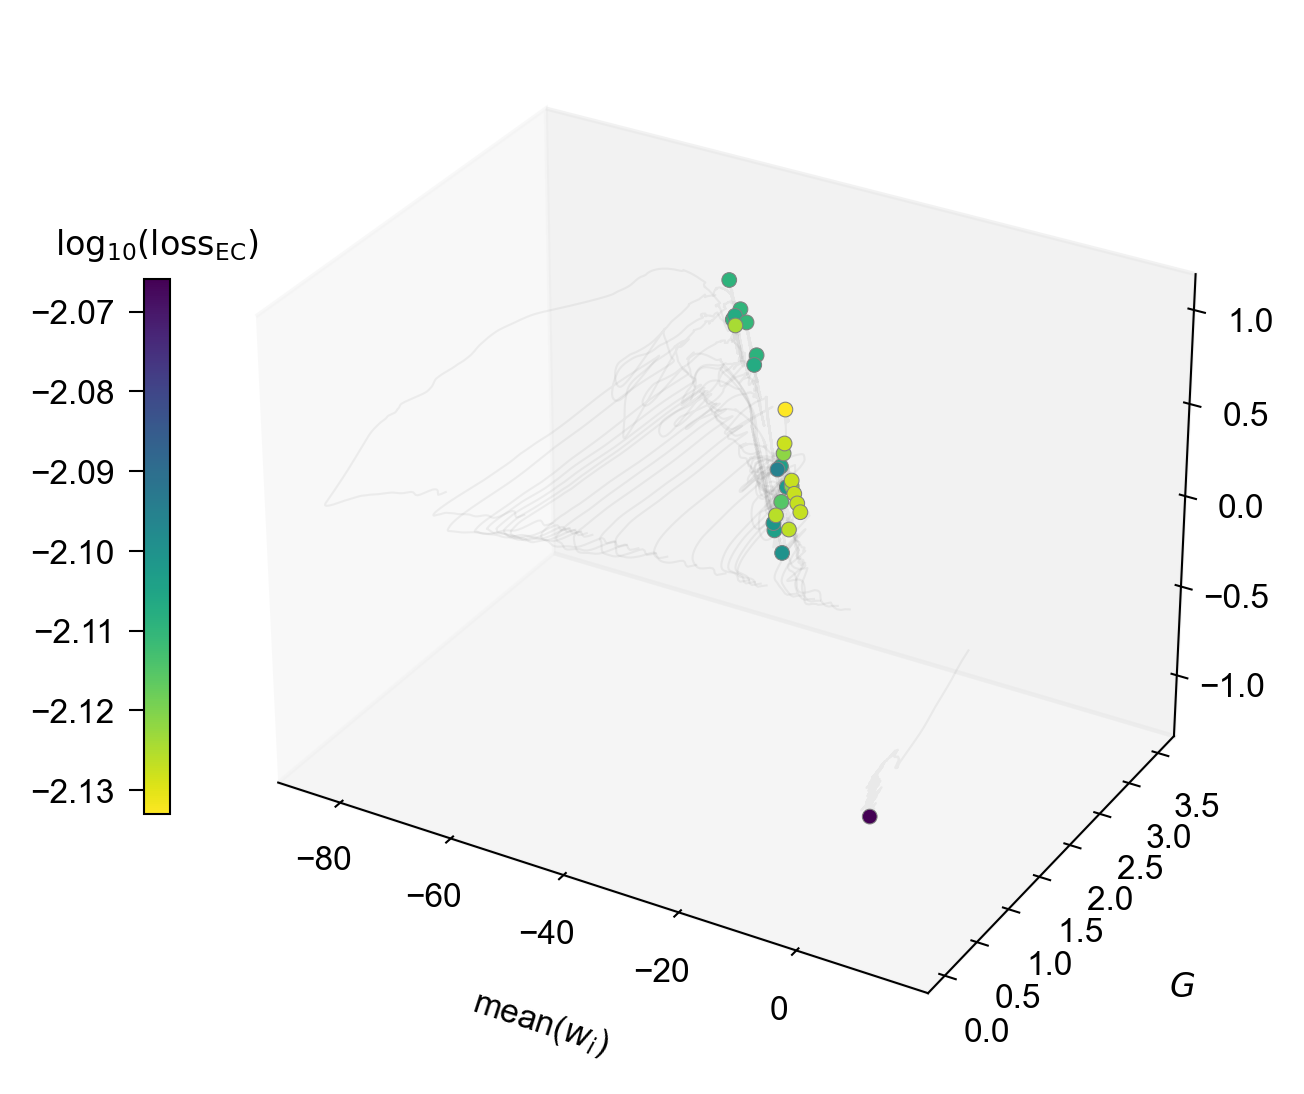

In [18]:
x=ancestor_results_EC['epoch_w'][ids,:,:].mean(axis=2)
y=np.abs(ancestor_results_EC['epoch_G'][ids,:])
z=ancestor_results_EC['epoch_I'][ids,:,:].mean(axis=2)

# c = np.log10(training_results_FC['epoch_FCloss'][ids,:]) # FC's loss
# clb_tit = r'$\mathrm{log_{10}(loss_{FC})}$'
# vmax = 'half'

c = np.log10(ancestor_results_EC['epoch_ECloss'][ids,:]) # ancestor_results_EC's loss
clb_tit = r'$\mathrm{log_{10}(loss_{EC})}$'
vmax = 'half'

c[np.isnan(c)] = np.nanmax(c)

fig = plt.figure(figsize=(130 * MM, 90 * MM),layout='constrained')
ax = fig.add_subplot(111, projection='3d')
img,clb = plot_traces3D(ax,x,y,z,c,vmax=vmax,colored_trace_alpha=1, if_gray_trace=True,gray_trace_alpha=.1)
img.set_edgecolors('gray')
img.set_linewidths(0.25)
img.set_sizes([50])

# ax.view_init(elev=23, azim=-62)

ax.tick_params(pad=0,  length=2, width=.5)
ax.set_xlabel('mean($w_i$)')
ax.set_ylabel('$G$')
ax.set_zlabel('mean($I_i$)')
clb.ax.set_title(clb_tit)
ax.grid(False)
ax.set_box_aspect((1.4, 1.0, 1.0))
fig.set_constrained_layout_pads(w_pad=1.2*MM, h_pad=1.2*MM)

## heirachy results

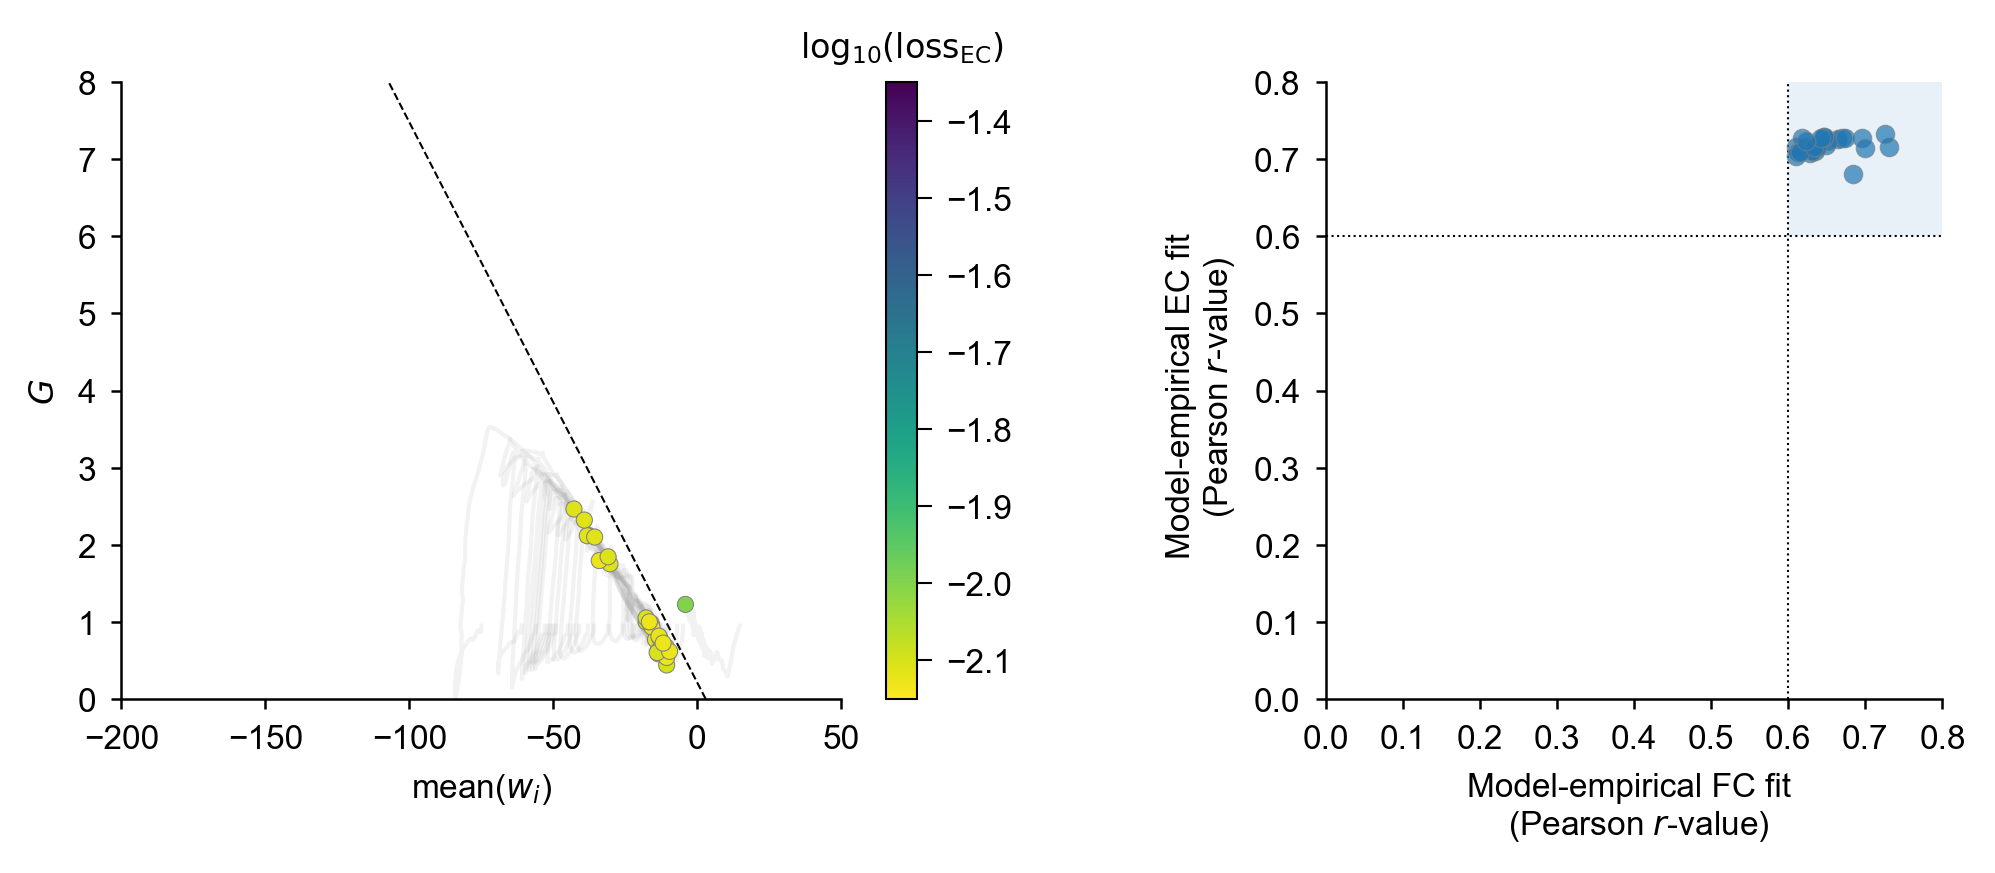

In [19]:
from matplotlib.patches import Rectangle

fig,axs=plt.subplots(1,2,figsize=(180*MM,75*MM))

ax=axs[0]

img,clb = plot_traces2D(ax,x,y,c,vmax=-1.35,vmin=-2.15,colored_trace_alpha=1, if_gray_trace=True,gray_trace_alpha=.1)
img.set_edgecolors('gray')
img.set_linewidths(0.25)
img.set_sizes([60])

style_axis(ax)

ax.set_xlabel('mean($w_i$)')
ax.set_ylabel('$G$')
clb.ax.set_title(clb_tit)
set_clb_same_height(ax,clb,)
lin_w = np.array([-200,50]);lin_G = np.array([0,8.0])# 画critical line
plot_dashed_lines(ax,phase_transition_lin_w(lin_G),lin_G,lin_w,lin_G)

ax=axs[1]
style_axis(ax)


fc_fit = r_FC_fc[ids]
ec_fit = r_EC_ec[ids]
high_fit = (fc_fit >= .6) & (ec_fit >= .6)
ax.scatter(
    fc_fit[~high_fit], ec_fit[~high_fit], s=20, color='#69A7CF', alpha=0.5,
    edgecolors='gray', linewidth=.25, zorder=2,
)
ax.scatter(
    fc_fit[high_fit], ec_fit[high_fit], s=20,
    color='tab:blue', alpha=0.7,
    edgecolors='gray',linewidth=.25, zorder=3,
)


ax.set_xlabel('Model-empirical FC fit \n (Pearson $r$-value)', )
ax.set_ylabel('Model-empirical EC fit \n (Pearson $r$-value)', )


xmax=.8
ymax=.8
ax.set_xlim([0,xmax]);ax.set_ylim([0,ymax])
ax.set_xticks(np.arange(9)/10)
ax.set_aspect('equal', adjustable='box')
ax.plot([0,xmax],[0.6,0.6],':k',zorder=0)
ax.plot([0.6,0.6],[0,ymax],':k',zorder=0)

Rectangle_xy=(.6,.6)
highlight = Rectangle(Rectangle_xy, xmax - Rectangle_xy[0], ymax - Rectangle_xy[1], linewidth=1, edgecolor=None, facecolor='#E8F1F7', alpha=1, label='Highlighted Area',zorder=-1)
ax.add_patch(highlight)

fig.tight_layout()

In [20]:

def plot_violin_corr_Parameter_Hierarchy(ax,rs,parameterID,hierarchyID_plt,legend=False,asterisk_gap=.2,asterisk_loc_xs=[-.29, -.02, .25]):

    columns=['spearman ρ-value','Hierarchy','Parameters']
    df = pd.DataFrame(columns=columns)
    for i in range(len(hierarchyID_plt)):
        df=pd.concat([df,pd.DataFrame({columns[0]:rs[:,i],columns[1]:hierarchyID_plt[i],columns[2]:parameterID})])

    sns.violinplot(ax=ax,x=columns[2], y=columns[0] ,hue=columns[1], data=df, legend=legend, 
                   linecolor='Black', gap=.1, linewidth=.5, inner='box',)


    # sns.stripplot(ax=ax,x=columns[2], y=columns[0] ,hue=columns[1], data=df, legend=legend, linewidth=0,
    #               dodge=True, jitter=0.35, size=2.5, alpha=.75)

    for i in range(len(hierarchyID_plt)):
        
        r = rs[:,i]

        tvalue,pvalue=scipy.stats.ttest_1samp(r,0)
        print("One-sample T-test of rous of ({},{}), T={}, p={} ".format(parameterID,hierarchyID_plt[i],tvalue, pvalue))

        if pvalue < .005 :
            sig = '*'
        else:
            sig = 'n.s.'

        if tvalue>0:
            loc_y = r.max() + asterisk_gap
        else:
            loc_y = r.min() - asterisk_gap

        ax.text(asterisk_loc_xs[i], loc_y, sig)

26
One-sample T-test of rous of ($w_i$,T1w/T2w), T=-12.064879612226353, p=6.398312873039706e-12 
One-sample T-test of rous of ($w_i$,PV), T=-12.046453216185055, p=6.611712653279851e-12 
One-sample T-test of rous of ($w_i$,SST), T=19.303917721833336, p=1.5569076713558394e-16 
One-sample T-test of rous of ($I_i$,T1w/T2w), T=18.599626869752264, p=3.719536450788055e-16 
One-sample T-test of rous of ($I_i$,PV), T=17.490303409949288, p=1.5568457731226817e-15 
One-sample T-test of rous of ($I_i$,SST), T=-19.99813379286336, p=6.77855214724046e-17 
One-sample T-test of rous of ($σ_i$,T1w/T2w), T=-22.960261867056357, p=2.5482022525016602e-18 
One-sample T-test of rous of ($σ_i$,PV), T=-20.924231724370888, p=2.3245039133192144e-17 
One-sample T-test of rous of ($σ_i$,SST), T=20.850615709135695, p=2.5269627357009604e-17 


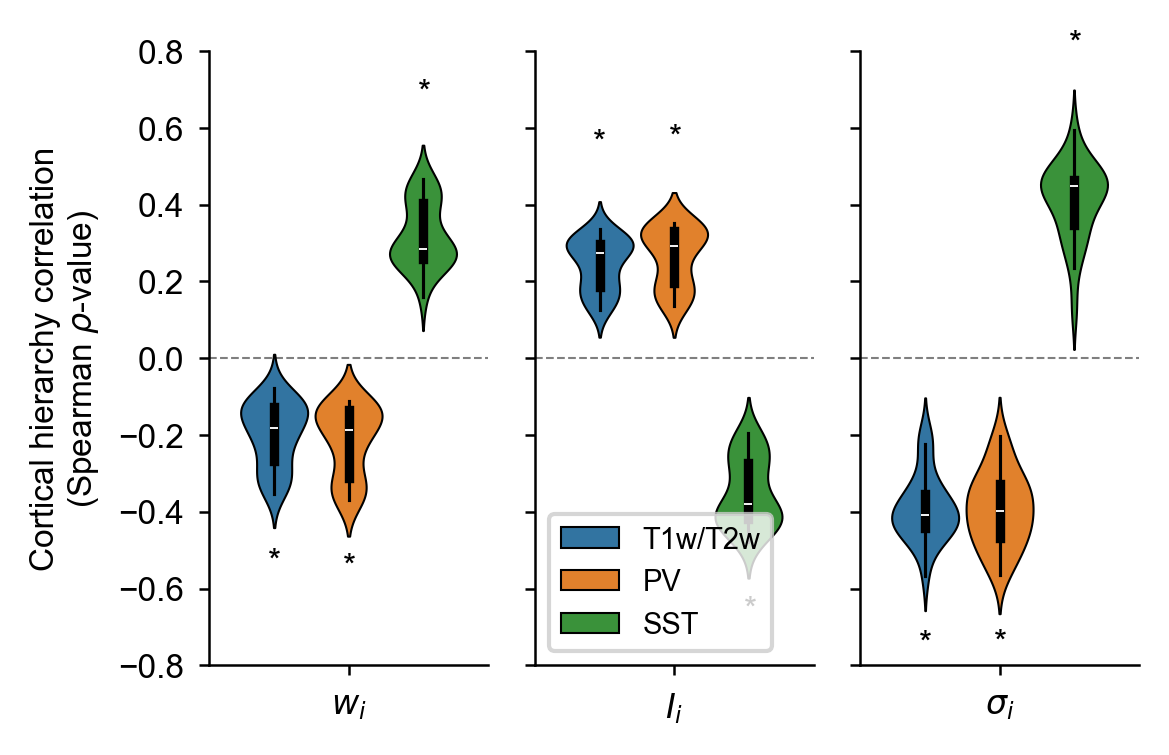

In [21]:
ids = ids_noNaN & (training_results_FC['scale_largerLRforW']==1) & (training_results_FC['lr']==0.1) & (r_FC_fc>0.6) & (r_EC_ec>0.6)
ids26 = ids
print(ids.sum())

fig,axs=plt.subplots(1,3,figsize=(100*MM,65*MM))
for ax in axs: style_axis(ax)



ax=axs[0]



rs=corr(training_results_FC['epoch_w'][ids,-1,:], hierarchy[:,:3].T, mask=np.ones(N,dtype=bool), style='pairwise', corrtype='spearman', implement='array')
plot_violin_corr_Parameter_Hierarchy(ax,rs,'$w_i$',hierarchyID_plt[:3])

ax=axs[1]
rs=corr(training_results_FC['epoch_I'][ids,-1,:], hierarchy[:,:3].T, mask=np.ones(N,dtype=bool), style='pairwise', corrtype='spearman', implement='array')
plot_violin_corr_Parameter_Hierarchy(ax,rs,'$I_i$',hierarchyID_plt[:3],legend=True);ax.legend(loc='lower left')

ax=axs[2]
rs=corr(training_results_FC['epoch_sigma'][ids,-1,:], hierarchy[:,:3].T, mask=np.ones(N,dtype=bool), style='pairwise', corrtype='spearman', implement='array')
plot_violin_corr_Parameter_Hierarchy(ax,rs,'$σ_i$',hierarchyID_plt[:3],asterisk_gap=.2)

axs[0].set_ylabel('Cortical hierarchy correlation\n(Spearman $\\rho$-value)')

for ax in axs[1:]:
    ax.set_ylabel('')
    ax.set_yticklabels('')

for ax in axs:
    ax.set_xlabel('')
    ax.set_xlim(ax.get_xlim())
    ax.set_ylim([-.8,.8])
    ax.plot(ax.get_xlim(),[0,0],'k--',alpha=.5,linewidth=.5,zorder=0)

plt.tight_layout()

plot time series of 0-input for these 26 retained results

In [22]:
bm.set_dt(5e-4) # second; 2000Hz sample rate
bm.set_mode(bm.batching_mode)

# plot time series of EC for these 26 retained results
G = bm.asarray(training_results_FC['epoch_G'][ids,-1])
w = bm.asarray(training_results_FC['epoch_w'][ids,-1,:])
I = bm.asarray(training_results_FC['epoch_I'][ids,-1,:])
sigma = bm.asarray(training_results_FC['epoch_sigma'][ids,-1,:])

duration = 4000
TSs = bm.zeros((G.size,duration,N))
restinput = bm.zeros((1,duration,N))
warmupinput = bm.zeros((1,1,N))
run0input = def_bodyFC(bm.asarray(struc_conn_matrix), restinput, warmupinput=warmupinput, ifoutBalloon=False)

# for i in range(G.size):
#     TS,_=run0input(G[i],w[i],I[i],sigma[i],S=0)
#     TSs[i,:,:] = bm.squeeze(TS)

In [23]:
i=0

0


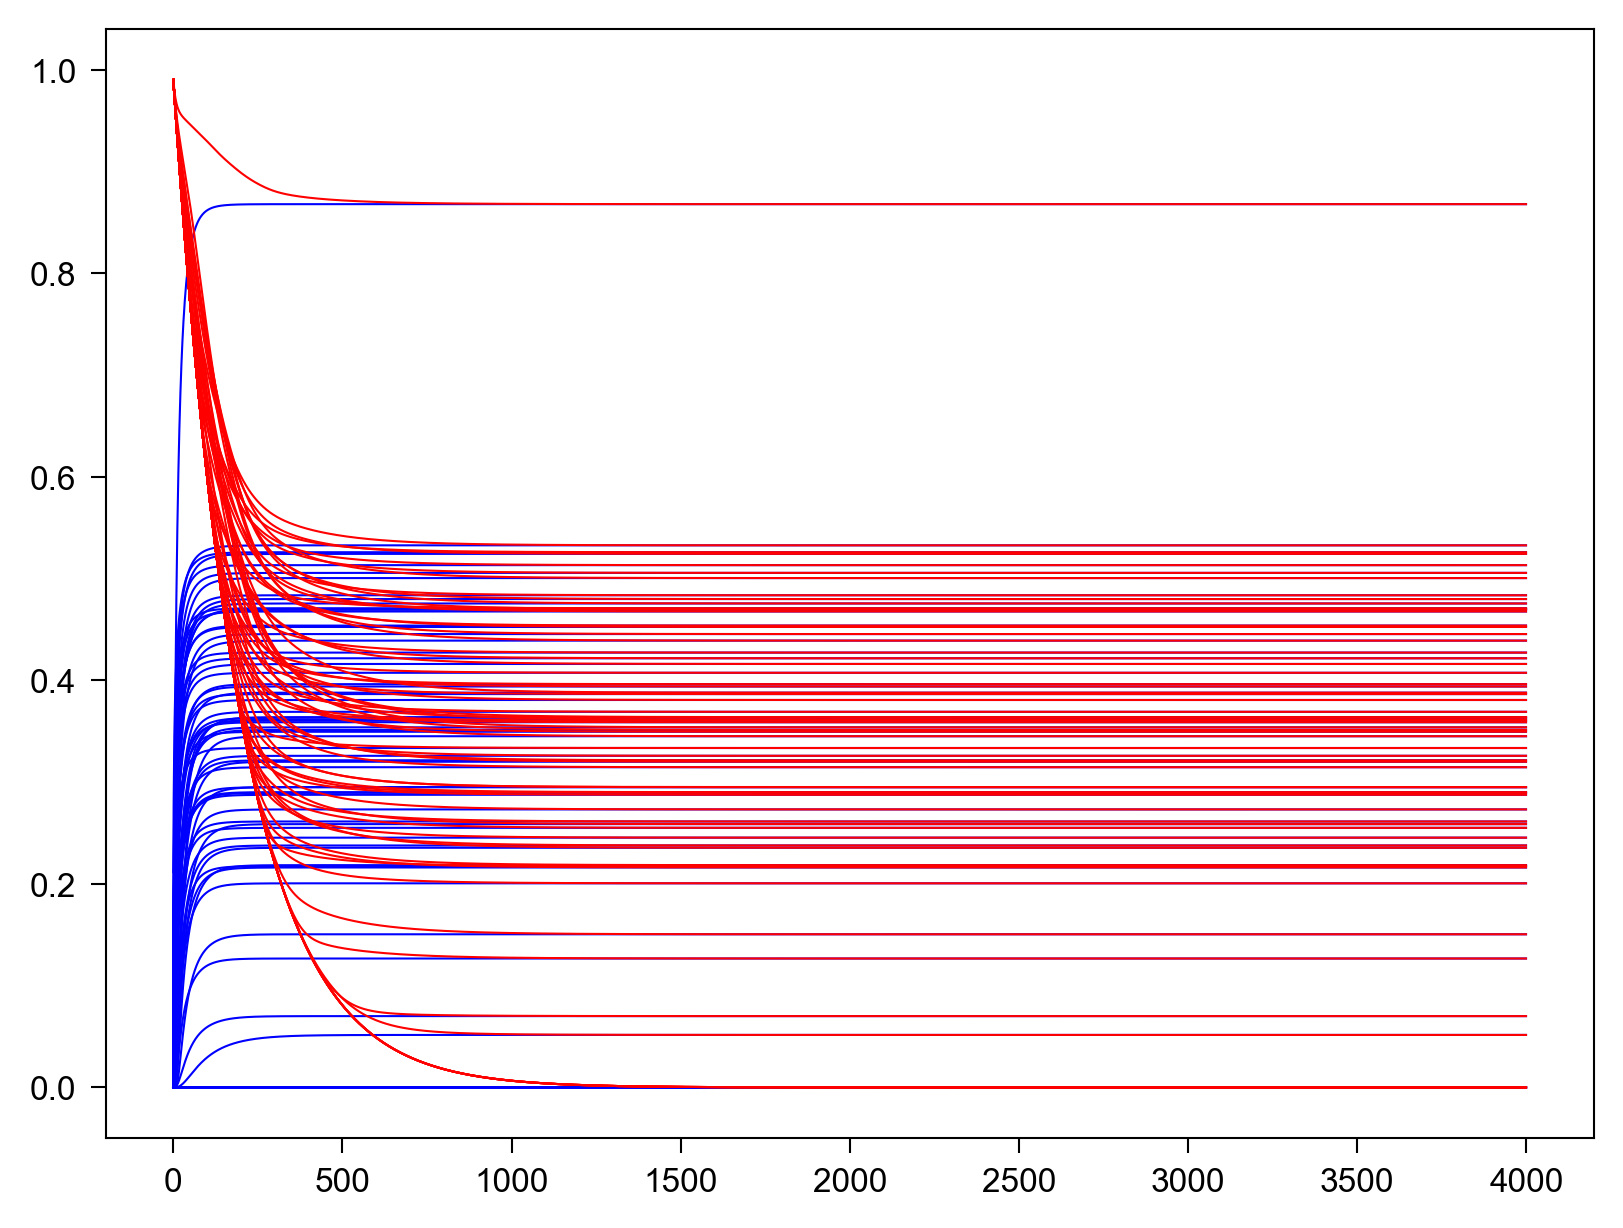

In [24]:
print(i)
TS1,_=run0input(G[i],w[i],I[i],sigma[i],S=1)
TS0,_=run0input(G[i],w[i],I[i],sigma[i],S=0)
plt.plot(TS0[0,:,:],'b')
plt.plot(TS1[0,:,:],'r')
plt.show()
i += 1


x mean (0.9580135008121492) and std (0.01961551810007524)
y mean (0.759550003645989) and std (0.04895675091335174)


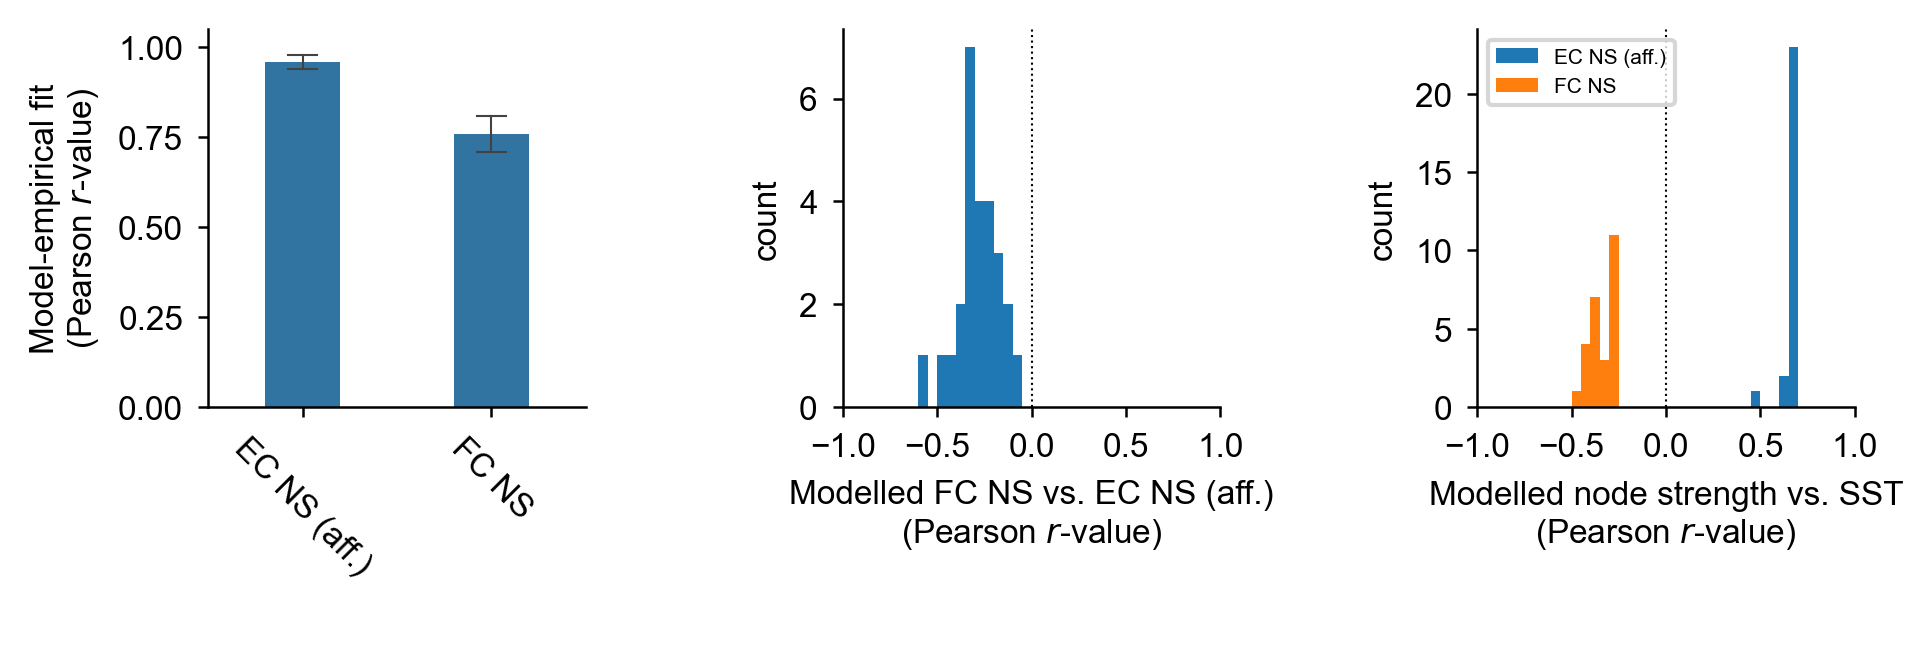

In [25]:
fig,axs=plt.subplots(1,3,figsize=(170/25.4,55/25.4))

for ax in axs: style_axis(ax)

x=np.squeeze(rNSaff_EC_ec[ids])
y=np.squeeze(rNS_FC_fc[ids])
z=np.squeeze(rNS_FC_EC[ids])
print(f'x mean ({x.mean()}) and std ({x.std()})')
print(f'y mean ({y.mean()}) and std ({y.std()})')

ax = axs[0]

df = pd.DataFrame({' ': ['EC NS (aff.)']*x.size + ['FC NS']*y.size,'EC': np.concatenate([x, y])})
sns.barplot(ax=ax,data=df,x=df.keys()[0],y=df.keys()[1],
            width=0.4,estimator="mean",errorbar="sd",capsize=0.15, err_kws={"linewidth": .5})
ax.tick_params(axis="x", labelrotation=-45)
ax.set_ylim([0,1.05])
ax.set_yticks([0,.25,.5,.75,1])
ax.set_box_aspect(1)

ax.set_ylabel('Model-empirical fit\n(Pearson $r$-value)')


# ax.scatter(x,y, marker='o', alpha=.5 )
# hb=ax.hexbin(x,y, gridsize=25, extent=(-1,1,-1,1),bins='log', cmap='viridis', zorder=1)
# cb=fig.colorbar(hb, ax=ax,)
# cb.ax.set_title('count')
# ax.grid(linestyle='--',)
# ax.set_axisbelow(True)
# ax.set_box_aspect(1)
# ax.set_ylim([-1,1])
# ax.set_xlim([-1,1])
# ax.set_xticks([-1,-.5,0,.5,1])
# ax.set_yticks([-1,-.5,0,.5,1])
# ax.set_ylabel('Model-empirical FC NS fit\nr-value', fontsize=6)
# ax.set_xlabel('r-value\nModel-empirical EC NS (aff.) fit', fontsize=6)

ax = axs[1]
ax.hist(z,bins=np.arange(-1,1,0.05),color="tab:blue",
    histtype="stepfilled",
    edgecolor="none",
    linewidth=0)
ax.set_xlabel("Modelled FC NS vs. EC NS (aff.)\n(Pearson $r$-value)")
ax.set_ylabel('count')
ax.set_xticks([-1,-.5,0,.5,1])

ax.set_box_aspect(1)
ax.set_xlim([-1,1])
ax.set_ylim(ax.get_ylim())

# r = -0.568
# ax.plot(np.ones(2)*r,ax.get_ylim(),'r:', label='Empirical')
# ax.legend(fontsize=5)

ax.plot(np.zeros(2),ax.get_ylim(),'k:')



ax = axs[2]

sst_idx = hierarchyID_plt.tolist().index('SST')

ec_sst=np.squeeze(rNSaff_EC_hie[ids,sst_idx])
fc_sst=np.squeeze(rNS_FC_hie[ids,sst_idx])

ax.hist(ec_sst,bins=np.arange(-1,1,0.05),color="tab:blue",
    histtype="stepfilled",
    edgecolor="none",
    linewidth=0,label='EC NS (aff.)')
ax.hist(fc_sst,bins=np.arange(-1,1,0.05),color="tab:orange",
    histtype="stepfilled",
    edgecolor="none",
    linewidth=0,label='FC NS')

ax.set_xlabel('Modelled node strength vs. SST\n(Pearson $r$-value)')
ax.set_ylabel('count')
ax.set_xticks([-1,-.5,0,.5,1])

ax.set_box_aspect(1)
ax.set_xlim([-1,1])
ax.set_ylim(ax.get_ylim())

# r =  0.681
# ax.plot(np.ones(2)*r,ax.get_ylim(),'b:', linewidth=1, label='Empirical EC NS (aff.)')

# r = -0.572
# ax.plot(np.ones(2)*r,ax.get_ylim(),'r:', linewidth=1, label='Empirical FC NS')

ax.legend(fontsize=5)

ax.plot(np.zeros(2),ax.get_ylim(),'k:')

plt.tight_layout()


# Plot result of the optimally-trained case

In [26]:
ids = best_with_filter(r_EC_ec+r_FC_fc, type='max', filter=ids_noNaN & (training_results_FC['scale_largerLRforW']==1) & (training_results_FC['lr']==0.1))
idsbest = ids

print(npz_file_FC['bppaths'][ids])
print('r_FC_fc =', r_FC_fc[ids], 'r_FC_fc_indirect =', r_FC_fc_indirect[ids],)
print('r_EC_ec =', r_EC_ec[ids], 'r_EC_ec_indirect =', r_EC_ec_indirect[ids],)

G=ancestor_states_EC[ids]['model']['DecoModel0']['DecoModel0.G']
w=ancestor_states_EC[ids]['model']['DecoModel0']['DecoModel0.w']
I=ancestor_states_EC[ids]['model']['DecoModel0']['DecoModel0.I']
sigma=states_FC[ids]['loss_fun_FC']['loss_function_FC0']['loss_function_FC0.sigma']

print(f'(G={G}, mean(w)={w.mean()}, mean(I)={I.mean()}, mean(sigma)={sigma.mean()})')
print(f'(G={G}, std(w)={w.std()}, std(I)={I.std()}, std(sigma)={sigma.std()})')

display('w=',w,'I=',I,'sigma=',sigma)

./checkpoints_FCstep/EC<G1.0_w-13.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm>FC<sigma1e-05_Adam_lr0.1_wLRx1_epo1k_outIdentity>.bp
r_FC_fc = 0.7261607166408809 r_FC_fc_indirect = 0.6979849182148088
r_EC_ec = 0.732643400019446 r_EC_ec_indirect = 0.48715000276584997
(G=0.9337772130966187, mean(w)=-15.770455360412598, mean(I)=0.9954909086227417, mean(sigma)=0.2808157801628113)
(G=0.9337772130966187, std(w)=7.514353275299072, std(I)=0.8232665657997131, std(sigma)=0.8897729516029358)


'w='

array([ -2.9448495,  -9.353083 , -16.48624  , -23.563951 , -11.453232 ,
       -17.162607 , -17.668444 , -18.576084 , -15.730789 , -18.256485 ,
       -14.959127 , -28.477566 , -13.806922 , -22.26118  , -11.11017  ,
       -14.113575 , -13.660574 ,  -8.324173 ,  -9.994807 , -16.892523 ,
       -14.781458 ,  -9.497952 , -19.048065 , -19.34278  ,  -9.68907  ,
       -21.087465 , -27.822239 , -38.323673 , -24.511578 , -15.184389 ,
       -20.016064 ,  -7.3904614,  -8.203187 , -23.457262 ,  -1.9078989,
       -10.185707 , -17.078823 , -13.151898 ,  -9.768889 , -12.56069  ,
       -21.49448  , -17.45849  , -25.332602 , -17.116861 , -15.298594 ,
       -19.453556 , -12.353594 , -20.583202 , -10.006827 , -12.572049 ,
       -11.125531 ,  -8.590333 , -10.992786 , -24.948622 , -16.320742 ,
        -9.953953 , -16.047106 , -25.3297   ,  -7.730514 , -19.067097 ,
       -29.489038 , -32.913956 , -18.95626  , -15.953722 ,  -4.9213457,
         6.5447707,  -5.04876  , -22.070168 ], dtype=float32)

'I='

array([ 0.40447006,  0.2582114 ,  0.7689504 ,  1.8458899 ,  0.4788377 ,
        0.6437866 ,  1.3660218 ,  1.2455229 ,  0.41689244,  1.9579556 ,
        0.68331414,  2.8941298 ,  0.50096214,  2.1647708 ,  0.20929073,
        1.0337957 ,  0.28939334,  0.1623374 ,  0.30959782,  1.3627181 ,
        0.55284995,  0.03857949,  1.1895188 ,  1.224672  ,  0.53513014,
        1.5295292 ,  2.1515877 ,  3.8469882 ,  2.2942038 ,  0.81483346,
        1.8485768 , -0.26595435,  0.29424903,  1.4263178 ,  0.37143221,
        0.27194905,  0.83414567,  0.24269454,  0.4893761 ,  0.420812  ,
        2.1936457 ,  0.84770316,  1.8003582 ,  1.4987317 ,  0.56336254,
        1.5712438 ,  0.66185164,  1.7408881 ,  0.28379774,  0.80860025,
        0.18782285,  0.13548449,  0.30792817,  1.6067224 ,  1.0247475 ,
        0.1706827 ,  0.818704  ,  2.000928  ,  0.2870175 ,  1.4541178 ,
        2.3975315 ,  2.5624173 ,  1.6074682 ,  1.0703928 , -0.34489638,
        0.1478544 ,  0.1107558 ,  1.0691752 ], dtype=float32)

'sigma='

array([ 6.69895709e-02,  4.27513987e-01,  1.89686203e+00, -6.94843382e-02,
        4.42625374e-01,  1.41774267e-01,  2.29629219e-01, -2.00476021e-01,
        3.72199488e+00,  6.08699918e-02,  4.28406090e-01, -8.29388201e-02,
        5.43576384e+00, -1.80108368e-01,  4.59454268e-01, -2.98692018e-01,
       -2.22088620e-01,  3.35276663e-01, -1.73817143e-01,  1.11964948e-01,
        2.01585579e+00,  3.43546659e-01,  1.49782777e-01, -2.84309328e-01,
        6.85821593e-01, -2.13902980e-01, -2.65786588e-01, -1.43824935e-01,
       -1.02476090e-01,  8.45311508e-02,  4.27991539e-01,  3.96231651e-01,
       -7.95109123e-02, -3.09131384e-01, -3.07015143e-03,  4.02467996e-01,
        1.61463812e-01,  1.01537451e-01,  2.86197811e-01,  1.71226393e-02,
       -7.78523386e-02, -9.35275033e-02, -2.81202585e-01, -5.24736941e-02,
        3.40313882e-01, -5.08583672e-02,  5.84524155e-01, -6.44280389e-02,
        3.06189924e-01, -3.00032914e-01, -1.82555914e-01,  2.37511799e-01,
       -1.22017711e-01,  

## the modelled connectome

In [27]:
model_FC = npz_file_FC['FCs_outBalloon'][ids]
model_EC = ECs[ids]

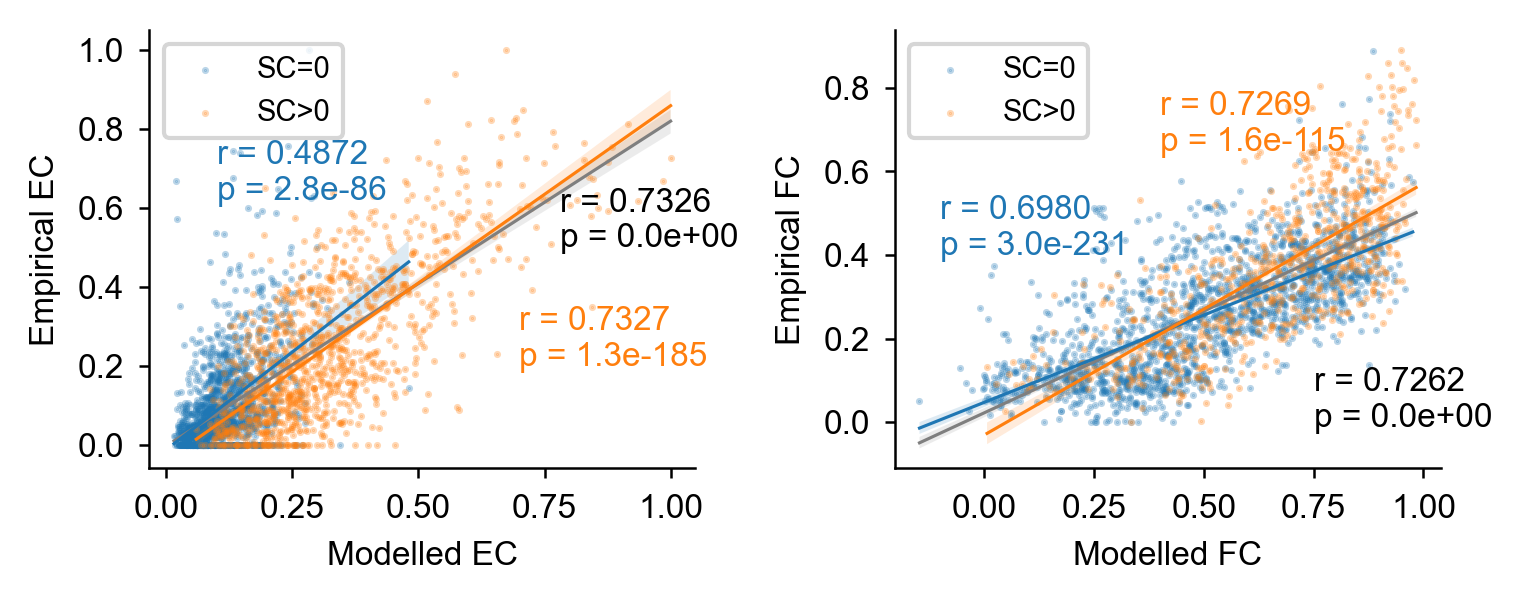

In [28]:
# plot correlation (edge level)

figsize=(130/25.4,52/25.4)
markersize=.5
alphadot=.3

fig,axs=plt.subplots(1,2,figsize=figsize)

ax=axs[0]
plot_conn_comparison_scatter(ax,rescale_EC(model_EC,ftract_ctx),ftract_ctx,sc_ctx,~np.isnan(ftract_ctx),(.78,.5),(.1,.62),(.7,.2),markersize=markersize,alphadot=alphadot)
ax.set_xlabel('Modelled EC',)
ax.set_ylabel('Empirical EC',)
ax.legend(loc='upper left')


ax=axs[1]
plot_conn_comparison_scatter(ax,model_FC,fc_ctx,sc_ctx,~np.isnan(mask_tril),(.75,-.01),(-.1,.4),(.4,.65),markersize=markersize,alphadot=alphadot)
ax.set_xlabel('Modelled FC',)
ax.set_ylabel('Empirical FC',)

for ax in axs: style_axis(ax)


plt.tight_layout()

/data/xyc/codes/xyc_github/EC-FC-BPTT-DecoModel/func_analysis.py:93: RuntimeWarning: Mean of empty slice
  NS_eff = np.nanmean(x,axis=-2) #按行计算求和，得到列的性质（最后第二维）：EC上刺激某节点，其他节点的平均响应（出度）efferent
/data/xyc/codes/xyc_github/EC-FC-BPTT-DecoModel/func_analysis.py:94: RuntimeWarning: Mean of empty slice
  NS_aff = np.nanmean(x,axis=-1) #按列计算求和，得到行的性质（最后第一维）：EC某节点的在刺激所有其他节点时的平均响应（入度）afferent


double check: r= -0.43470711155601965


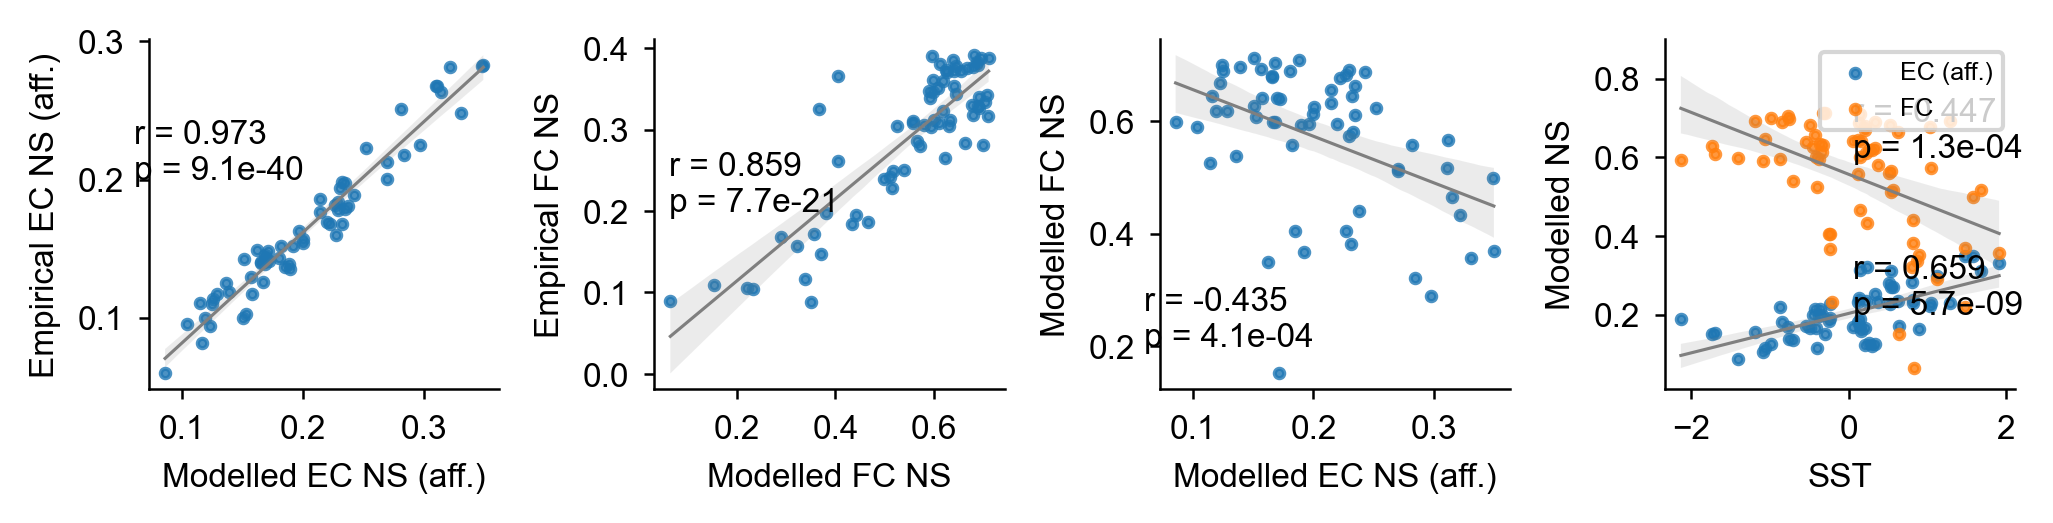

In [29]:
# plot correlation (node level)
model_NSfc,_ = node_strength(model_FC,fc_ctx)
model_NSeff,model_NSaff = node_strength(rescale_EC(model_EC,ftract_ctx),ftract_ctx)
print('double check: r=', rNS_FC_EC[ids])

def plot_scatter(ax,x,y,text_xy=(0,0),mask=None, label='',markersize=5,alphaline=1,cmap=plt.colormaps['tab10']):
    if mask is None:
        mask=(~np.isnan(x))&(~np.isnan(y))
    x=np.copy(x[mask])
    y=np.copy(y[mask])
    sns.regplot(ax=ax,x=x,y=y,label=label,scatter_kws={'s':markersize,},line_kws={"color": cmap(7),'alpha':alphaline})
    
    r,p=scipy.stats.pearsonr(x, y)
    if p>0.05:
        text="r = {:.3f}\np = {:.3f} (n.s.)".format(r,p)
    elif p<0.001:
        text="r = {:.3f}\np = {:.1e}".format(r,p)
    else:
        text="r = {:.3f}\np = {:.3f}".format(r,p)
    ax.text(text_xy[0],text_xy[1],text)

fig,axs=plt.subplots(1,4,figsize=(175/25.4,55/25.4))
for ax in axs: style_axis(ax);ax.set_box_aspect(1)

ax=axs[0]
plot_scatter(ax,model_NSaff,real_NSaff,(.06,.2))
ax.set_xlabel('Modelled EC NS (aff.)')
ax.set_ylabel('Empirical EC NS (aff.)')
plt.tight_layout()

ax=axs[1]
plot_scatter(ax,model_NSfc,real_NSfc,(.06,.2))
ax.set_xticks([.2,.4,.6,])
ax.set_xlabel('Modelled FC NS')
ax.set_ylabel('Empirical FC NS')
plt.tight_layout()

ax=axs[2]
plot_scatter(ax,model_NSaff,model_NSfc,(.06,.2))
ax.set_xlabel('Modelled EC NS (aff.)')
ax.set_ylabel('Modelled FC NS')

ax=axs[3]

sst_idx = hierarchyID_plt.tolist().index('SST')
sst = hierarchy[:,sst_idx]
plot_scatter(ax,sst,model_NSaff,(.06,.2),label='EC (aff.)')
plot_scatter(ax,sst,model_NSfc,(.06,.6),label='FC')
ax.legend(fontsize=6)
ax.set_xlabel('SST')
ax.set_ylabel('Modelled NS')
ax.set_ylim([0.01,.9])


plt.tight_layout()

## states along training

$w_i$ ['T1w/T2w' 'PV' 'SST'] [-0.28671769 -0.30364454  0.42461374]
$I_i$ ['T1w/T2w' 'PV' 'SST'] [ 0.28824461  0.33725558 -0.47994503]
$\sigma_i$ ['T1w/T2w' 'PV' 'SST'] [-0.56715592 -0.56571903  0.59408133]


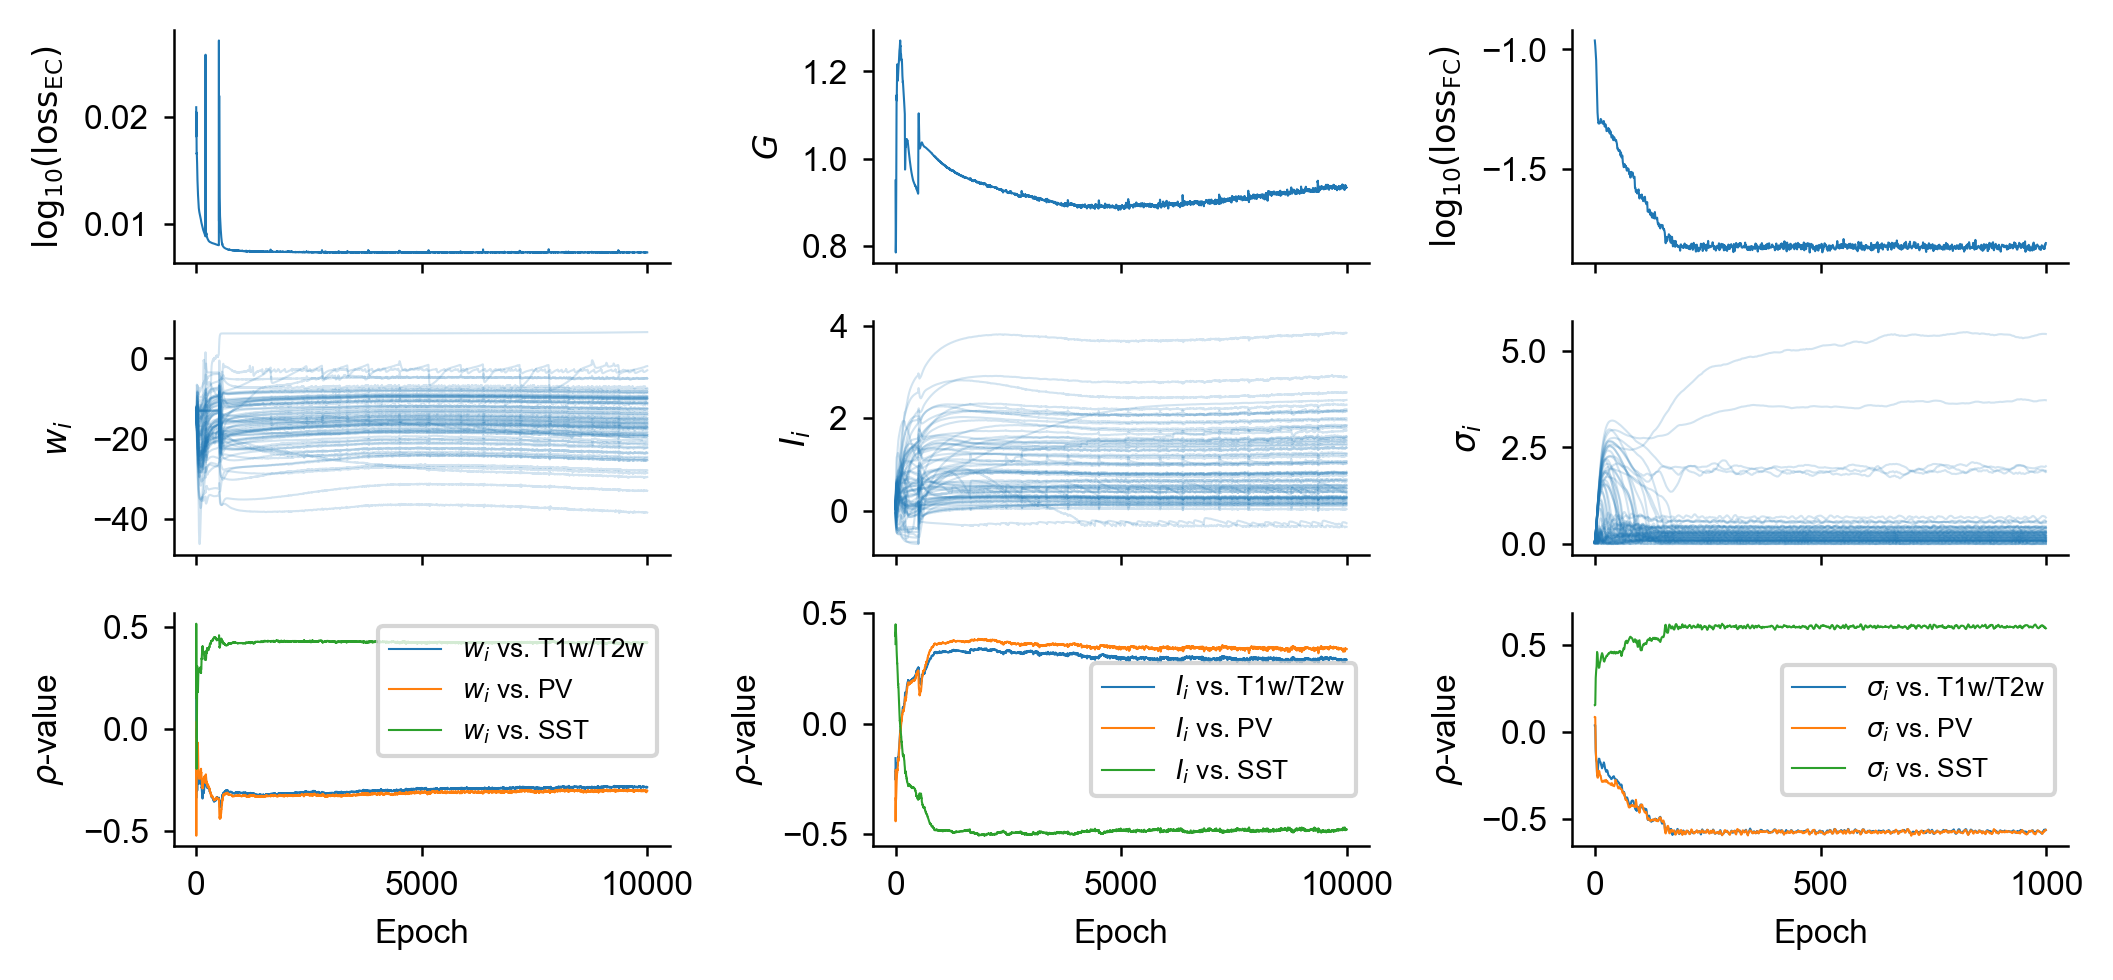

In [30]:
# plot parameters along training progress with their correlation to hierarchy
def plot_parameters_along_training(ax1,parameter,parameterID,line_alpha=.2,ax2=None,hierarchy=None,hierarchyID_plt=None,linewidth=.5,corrtype='spearman'):

    ax=ax1
    ax.plot(parameter,color='tab:blue',alpha=line_alpha,linewidth=linewidth)
    ax.set_ylabel(parameterID)

    if ax2 is not None:

        rs=corr(parameter, hierarchy.T, mask=None, style='pairwise', corrtype=corrtype, implement='array')

        ax=ax2

        legend_labels = [parameterID +' vs. ' + i for i in hierarchyID_plt]

        ax.plot(rs,label=legend_labels,linewidth=linewidth)
        ax.legend(fontsize=6.3)
        ax.set_yticks([-.5,0,.5])
        # tit= 'Cortical hierarchy vs. {}'.format(parameterID)
        # ax.set_title(tit, fontsize=7, loc='left')
        ax.set_ylabel('$\\rho$-value')

        print(parameterID,hierarchyID_plt,rs[-1])


fig,axs=plt.subplots(3,3,figsize=(60*3*MM,28*3*MM))

for ax in axs.flat: style_axis(ax)

plot_parameters_along_training(axs[0,0],ancestor_results_EC['epoch_ECloss'][ids,:],r'$\mathrm{log_{10}(loss_{EC})}$',1)
plot_parameters_along_training(axs[0,1],ancestor_results_EC['epoch_G'][ids,:],'$G$',1)
plot_parameters_along_training(axs[1,0],ancestor_results_EC['epoch_w'][ids,:],'$w_i$',ax2=axs[2,0],hierarchy=hierarchy[:,:3],hierarchyID_plt=hierarchyID_plt[:3])
plot_parameters_along_training(axs[1,1],ancestor_results_EC['epoch_I'][ids,:],'$I_i$',ax2=axs[2,1],hierarchy=hierarchy[:,:3],hierarchyID_plt=hierarchyID_plt[:3])

plot_parameters_along_training(axs[0,2],np.log10(training_results_FC['epoch_FCloss'][ids,:]),r'$\mathrm{log_{10}(loss_{FC})}$',1)
plot_parameters_along_training(axs[1,2],training_results_FC['epoch_sigma'][ids,:],'$\sigma_i$',ax2=axs[2,2],hierarchy=hierarchy[:,:3],hierarchyID_plt=hierarchyID_plt[:3])

for i in range(2):
    for j in range(3):
        axs[i,j].set_xticklabels([])

axs[2,0].set_xlabel("Epoch",)
axs[2,1].set_xlabel("Epoch",)
axs[2,2].set_xlabel("Epoch",)

fig.tight_layout()


# test theory retained 26 cases

## time series of resting-0-input for 26 retained results with obtained S*


In [31]:
bm.set_dt(5e-4) # second; 2000Hz sample rate
bm.set_mode(bm.batching_mode)

Text(0.02, 0.5, '$S_i$')

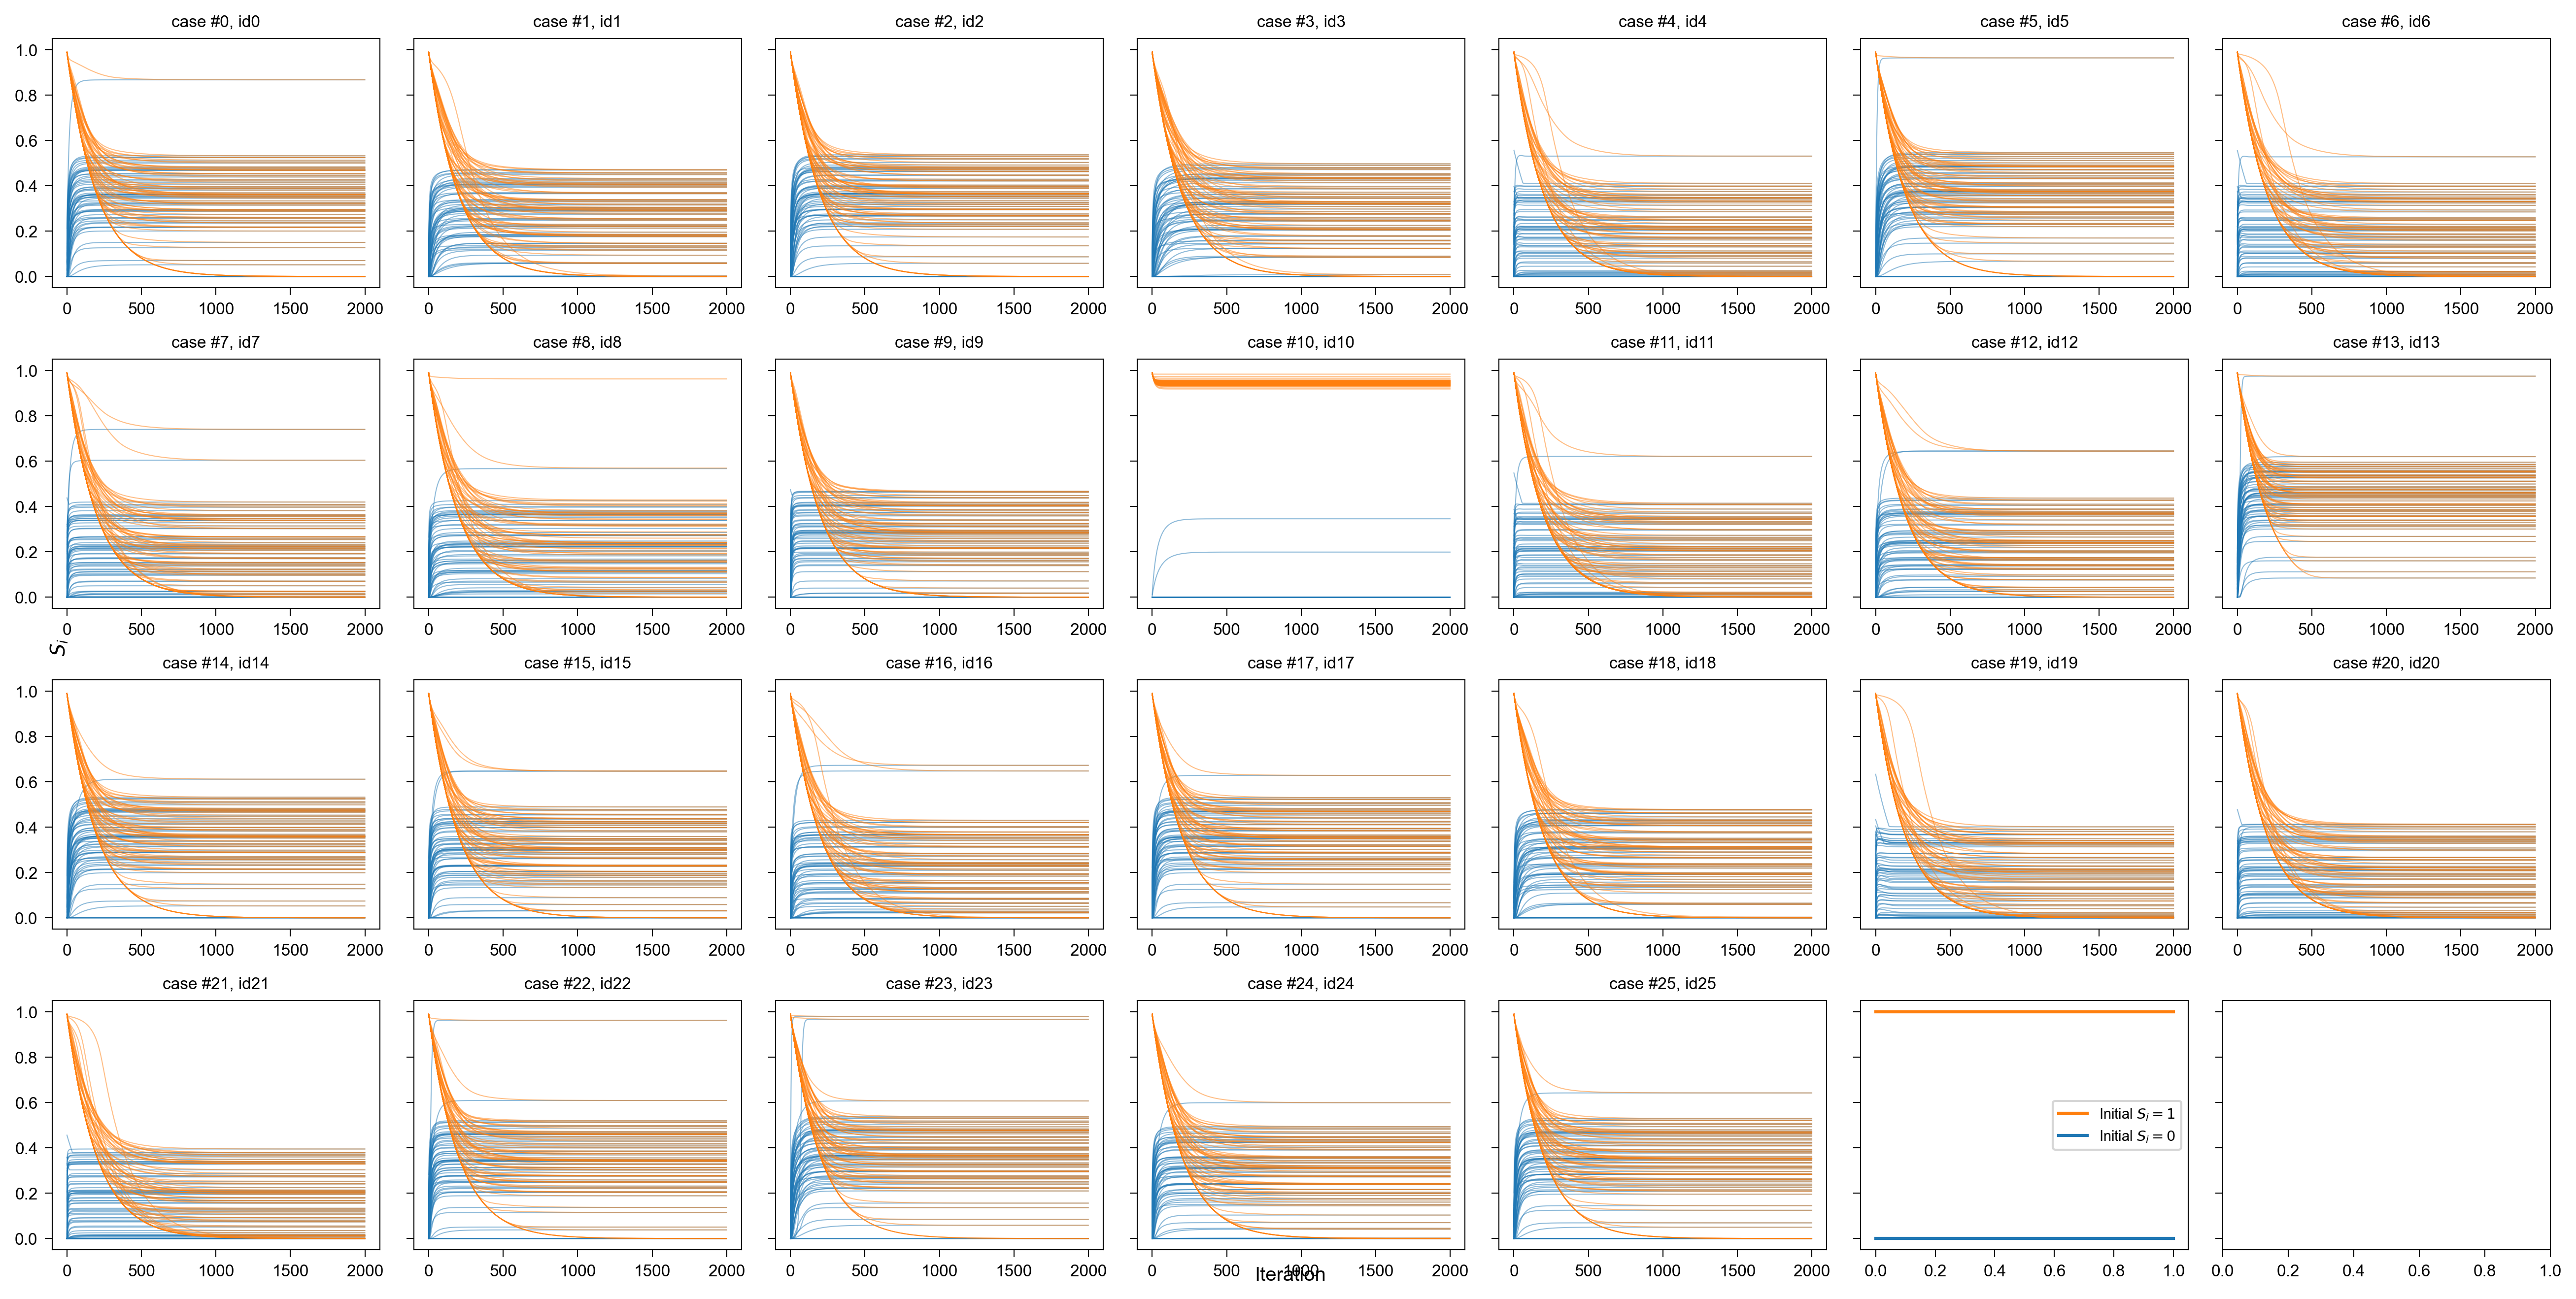

In [32]:
ids=ids26

# plot time series of EC for these 26 retained results
G = bm.asarray(training_results_FC['epoch_G'][ids,-1])
w = bm.asarray(training_results_FC['epoch_w'][ids,-1,:])
I = bm.asarray(training_results_FC['epoch_I'][ids,-1,:])
sigma = bm.asarray(training_results_FC['epoch_sigma'][ids,-1,:])

duration = 2000
TSs = bm.zeros((G.size,duration,N))
restinput = bm.zeros((1,duration,N))
warmupinput = bm.zeros((1,1,N))
run0input = def_bodyFC(bm.asarray(struc_conn_matrix), restinput, warmupinput=warmupinput, ifoutBalloon=False)

fig, axs = plt.subplots(4, 7, figsize=(7*2.5, 4*2.2),sharey=True)
axs = axs.flatten()

for i in range(G.size):

    TS1,_=run0input(G[i],w[i],I[i],sigma[i],S=1)
    TS0,_=run0input(G[i],w[i],I[i],sigma[i],S=0)
    axs[i].plot(TS0[0,:,:],'tab:blue', lw=0.5, alpha=0.5)
    axs[i].plot(TS1[0,:,:],'tab:orange', lw=0.5, alpha=0.5)
    axs[i].set_title(f'case #{i}, id{np.where(ids26)[0][i]}')

i += 1
axs[i].plot([1,1],'tab:orange', label='Initial $S_i = 1$', lw=1.5,)
axs[i].plot([0,0],'tab:blue',   label='Initial $S_i = 0$', lw=1.5,)
axs[i].legend()
fig.tight_layout()
fig.supxlabel('Iteration')
fig.supylabel('$S_i$')

## calculate analytcial EC/FC

In [33]:
from pathlib import Path
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from func_theory import get_S_star, theory_ECFC

# 直接复用上文保存的 ids26，不修改 ids/G/w/I/sigma。
theory_case_indices = np.flatnonzero(ids26)
if theory_case_indices.size == 0:
    raise ValueError('ids26 is empty; run the retained-case selection cell first.')
print(f'Retained cases: {theory_case_indices.size} (original dataset: 26)')

# SigmaOnly 训练中 G/w/I 固定；epoch 末值即前向模拟所用参数。
theory_G = np.asarray(training_results_FC['epoch_G'][theory_case_indices, -1], dtype=float)
theory_w = np.asarray(training_results_FC['epoch_w'][theory_case_indices, -1, :], dtype=float)
theory_I = np.asarray(training_results_FC['epoch_I'][theory_case_indices, -1, :], dtype=float)
# 与 get_parallel_parameters_from_bppaths 保持一致：读取保存的最终 sigma，
# 保存值可有正负号；前向模拟使用 abs(sigma)，理论使用 sigma**2，约定一致。
theory_sigma = np.stack([
    np.broadcast_to(np.asarray(
        states_FC[case_index]['loss_fun_FC']['loss_function_FC0']['loss_function_FC0.sigma'],
        dtype=float,
    ), (N,))
    for case_index in theory_case_indices
])

# ECs 在上文已按 ancestor_bppaths 对齐到 FC 的 case 顺序。
modelled_ECs = np.asarray(ECs[theory_case_indices], dtype=float)
modelled_FCs = {
    key: np.asarray(npz_file_FC[key][theory_case_indices], dtype=float)
    for key in ('FCs_outIdentity', 'FCs_outBalloon')
    if key in npz_file_FC.files
}
if 'FCs_outIdentity' not in modelled_FCs:
    raise KeyError('FCs_outIdentity is required for the primary neural-FC validation.')

theory_cases = pd.DataFrame({
    'case_index': theory_case_indices,
    'bppath': np.asarray(npz_file_FC['bppaths'])[theory_case_indices],
    'status': 'not run',
    'S_source': 'run0input (10 s)',
    'drift_residual': np.nan,
    'S_mean': np.nan,
    'max_real_eigenvalue': np.nan,
})


Retained cases: 26 (original dataset: 26)


## obtain analytical EC/FC and related info

In [34]:
# 在这里一次性计算 trained sigma 和 homogeneous sigma=1 两套 EC/FC/info。
# 后续分析直接复用缓存；EC、Jacobian 不依赖 sigma，两套结果应相同。

theory_shape = (theory_case_indices.size, N, N)
theory_ECs, theory_FCs = [np.full(theory_shape, np.nan) for _ in range(2)]
theory_ECs_homogeneous, theory_FCs_homogeneous = [np.full(theory_shape, np.nan) for _ in range(2)]
theory_info = [None] * theory_case_indices.size
theory_info_homogeneous = [None] * theory_case_indices.size


theory_cases['S_source'] = 'get_S_star (S=1)'

for case_pos in range(theory_case_indices.size):
    try:
        case_parameters = (
            struc_conn_matrix, theory_G[case_pos], theory_w[case_pos], theory_I[case_pos],
        )
        S_star = get_S_star(*case_parameters, S=1.0)
        for noise, ecs, fcs, infos in (
            (theory_sigma[case_pos], theory_ECs, theory_FCs, theory_info),
            (1.0, theory_ECs_homogeneous, theory_FCs_homogeneous, theory_info_homogeneous),
        ):
            ec, fc, info = theory_ECFC(
                *case_parameters, noise, S_star=S_star, return_info=True,
            )
            if not all(np.isfinite(a).all() for a in (ec, fc)):
                raise ValueError('Non-finite theoretical EC/FC.')
            ecs[case_pos], fcs[case_pos], infos[case_pos] = ec, fc, info

        info = theory_info[case_pos]
        theory_cases.loc[case_pos, 'status'] = 'ok'
        theory_cases.loc[case_pos, 'S_mean'] = info['S'].mean()
        theory_cases.loc[case_pos, 'drift_residual'] = info['equilibrium_residual']
        theory_cases.loc[case_pos, 'max_real_eigenvalue'] = np.linalg.eigvals(info['Jacobian']).real.max()
    except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
        # 不稳定/无物理稳态的 case 保留 NaN，并在表中显示原因。
        theory_cases.loc[case_pos, 'status'] = f'{type(exc).__name__}: {exc}'

print(f"Theory solved (trained + homogeneous sigma): {(theory_cases['status'] == 'ok').sum()}/{len(theory_cases)}")
if (theory_cases['status'] != 'ok').any():
    display(theory_cases.loc[theory_cases['status'] != 'ok', ['case_index', 'status']])


Theory solved (trained + homogeneous sigma): 26/26


In [35]:
# 所有 mask 及三类比较的选择统一在这里定义；True 表示参与计算。
# 三种基础 mask；ftract_ctx 的对角线已在前面设为 NaN。
mask_upper_triangle = np.triu(np.ones((N, N), dtype=bool), k=1)
mask_offdiagonal = ~np.eye(N, dtype=bool)
mask_empirical_ec = ~np.isnan(ftract_ctx)

# 比较 1：Modelled EC vs analytical EC，可独立选择 mask_offdiagonal / mask_empirical_ec
mask_modelled_ec_vs_analytical_ec = mask_offdiagonal

# 比较 2：Modelled FC vs analytical FC，固定使用上三角。
mask_modelled_fc_vs_analytical_fc = mask_upper_triangle

# 比较 3：Analytical EC NS vs FC NS，只切换 EC NS 的边集；FC 完整测量，NS 固定用非对角边。
mask_analytical_ec_ns = mask_offdiagonal # EC NS 可独立选择 mask_offdiagonal / mask_empirical_ec，与上面的 EC 矩阵比较互不影响。
mask_analytical_fc_ns = mask_offdiagonal

# 后续已有的 analytical EC-FC Edge 相关直接使用基础 mask_offdiagonal。


In [36]:
# 统一 EC 归一化：每个 case 先去对角，再对全部非对角边确定归一化尺度。
# 沿用现有公式 (EC - min) / max；min/max 仅沿每个矩阵的最后两维计算。
# 后续比较 mask 只负责选边，边图、NS 和 Edge 相关都复用这里的结果。
# 原始 EC 保留给 Xi 等理论计算；FC 已是相关系数，不额外归一化。
def normalize_ec_offdiagonal(matrices):
    ec = np.where(mask_offdiagonal, np.asarray(matrices, dtype=float), np.nan)
    ec_min = np.nanmin(ec, axis=(-2, -1), keepdims=True)
    ec_max = np.nanmax(ec, axis=(-2, -1), keepdims=True)
    return (ec - ec_min) / ec_max

modelled_ECs_normalized = normalize_ec_offdiagonal(modelled_ECs)
theory_ECs_normalized = normalize_ec_offdiagonal(theory_ECs)
theory_ECs_homogeneous_normalized = normalize_ec_offdiagonal(theory_ECs_homogeneous)


## comapre analytical and modelled

In [37]:
def theory_edge_fit(theoretical, simulated, edge_mask):
    # 只使用传入的比较 mask；选边后排除两侧任一值非有限的数据对。
    pairs = np.column_stack((theoretical[edge_mask], simulated[edge_mask]))
    pairs = pairs[np.isfinite(pairs).all(axis=1)]
    x_edges, y_edges = pairs.T
    n_edges = len(pairs)
    if n_edges < 3 or np.ptp(x_edges) == 0 or np.ptp(y_edges) == 0:
        return np.nan, np.nan, n_edges
    return float(pearsonr(x_edges, y_edges).statistic), float(spearmanr(x_edges, y_edges).statistic), n_edges

# EC 使用统一的去对角归一化结果，FC 保留相关系数原值；mask 直接引用统一定义。
theory_comparisons = {
    'EC': (theory_ECs_normalized, modelled_ECs_normalized, mask_modelled_ec_vs_analytical_ec),
}
for fc_key, simulated_fcs in modelled_FCs.items():
    theory_comparisons[fc_key] = (theory_FCs, simulated_fcs, mask_modelled_fc_vs_analytical_fc)

theory_fit_rows = []
for comparison, (theoretical, simulated, edge_mask) in theory_comparisons.items():
    for case_pos, case_index in enumerate(theory_case_indices):
        r_value, rho_value, n_edges = theory_edge_fit(
            theoretical[case_pos], simulated[case_pos], edge_mask,
        )
        theory_fit_rows.append({
            'case_index': int(case_index), 'comparison': comparison,
            'pearson_r': r_value, 'spearman_rho': rho_value, 'n_edges': n_edges,
        })

theory_fit = pd.DataFrame(theory_fit_rows)
theory_fit_table = theory_fit.pivot(index='case_index', columns='comparison', values='pearson_r')
theory_fit_table = theory_fit_table.reindex(index=theory_case_indices, columns=list(theory_comparisons))
print('Per-case Pearson r (analytical versus modelled):')
display(theory_cases.set_index('case_index').drop(columns='bppath').join(theory_fit_table).round(4))

theory_summary = theory_fit.groupby('comparison', sort=False)['pearson_r'].agg(
    ['count', 'mean', 'std', 'median', 'min', 'max']
)
print('Pearson r summary; count excludes failed/undefined cases:')
display(theory_summary.round(4))
# theory_fit 中还保存每个 case 的 Spearman rho 和有效边数；
# theory_info 中保存 S*、Jacobian 与 covariance，供进一步检查。


Per-case Pearson r (analytical versus modelled):


,status,S_source,drift_residual,S_mean,max_real_eigenvalue,EC,FCs_outIdentity,FCs_outBalloon
case_index,,,,,,,,
0,ok,get_S_star (S=1),0.0,0.3289,-10.0000,0.6689,0.7707,0.8513
1,ok,get_S_star (S=1),0.0,0.2501,-10.0000,0.6445,0.7037,0.7957
2,ok,get_S_star (S=1),0.0,0.3256,-10.0000,0.7042,0.6329,0.7797
3,ok,get_S_star (S=1),0.0,0.2736,-10.0000,0.7216,0.7248,0.7980
4,ok,get_S_star (S=1),0.0,0.1852,-10.0000,0.4243,0.6563,0.7894
5,ok,get_S_star (S=1),0.0,0.3490,-10.0000,0.7184,0.7026,0.8218
6,ok,get_S_star (S=1),0.0,0.1836,-10.0000,0.4260,0.6175,0.7251
7,ok,get_S_star (S=1),0.0,0.2059,-10.0000,0.4395,0.6661,0.7653
8,ok,get_S_star (S=1),0.0,0.2198,-10.0000,0.5309,0.7265,0.8626


Pearson r summary; count excludes failed/undefined cases:


,count,mean,std,median,min,max
comparison,,,,,,
EC,26,0.5942,0.1482,0.6131,0.3958,0.9664
FCs_outIdentity,26,0.7020,0.0803,0.7199,0.5516,0.8575
FCs_outBalloon,26,0.7615,0.1017,0.7935,0.3605,0.8626


## compare hetero and homo

In [38]:
# 固定 S*/G/w/I，比较 E 与同质/训练后异质 sigma 对应的 FC。
# 所有比较 mask 直接引用上方统一定义：EC NS 可切换，FC NS 始终使用非对角边。
# EC 直接使用统一归一化结果；EC/FC 在副本上按比较 mask 置 NaN 后计算 NS，不重新归一化。
# E_ij 表示 j -> i：afferent 为行均值，efferent 为列均值；FC 对称，两种 NS 一致。
# 已有的 EC-FC Edge 相关使用基础 mask_offdiagonal，与 EC NS 的选项独立。
# 输出 *_table（逐 case 相关性）、*_summary（跨 case 统计）、*_NS（逐节点强度），供下一块绘图。

theory_compare_hetero_homo_sigma_rows = {'FC (sigma=1)': [], 'FC (trained sigma)': []}
theory_compare_hetero_homo_sigma_NS = {}
ec_fc_matrices = {}
for pos, case_index in enumerate(theory_case_indices):
    ec = theory_ECs_normalized[pos].copy()
    ec[~mask_analytical_ec_ns] = np.nan

    fc_homo, fc_hetero = theory_FCs_homogeneous[pos], theory_FCs[pos]
    ec_fc_matrices[int(case_index)] = {'E': ec}

    ec_NSeff, ec_NSaff = node_strength(ec)
    case_NS = {'EC afferent': ec_NSaff, 'EC efferent': ec_NSeff}
    for label, fc_key, fc in (
        ('FC (sigma=1)', 'FC_homo', fc_homo),
        ('FC (trained sigma)', 'FC_hetero', fc_hetero),
    ):
        fc_ns = np.where(mask_analytical_fc_ns, fc, np.nan)
        ec_fc_matrices[int(case_index)][fc_key] = fc_ns
        _, fc_NS = node_strength(fc_ns)
        case_NS[label] = fc_NS
        # 经验 EC 可能有整行/整列缺失；corr 自动排除任一侧为 NaN 的节点。
        theory_compare_hetero_homo_sigma_rows[label].append([
            theory_edge_fit(theory_ECs_normalized[pos], fc, mask_offdiagonal)[0],
            corr(ec_NSaff, fc_NS)[0],
            corr(ec_NSeff, fc_NS)[0],
        ])
    theory_compare_hetero_homo_sigma_NS[int(case_index)] = case_NS

theory_compare_hetero_homo_sigma_table = pd.concat({
    label: pd.DataFrame(rows, index=pd.Index(theory_case_indices, name='case_index'),
                        columns=['Edge', 'NS afferent', 'NS efferent'])
    for label, rows in theory_compare_hetero_homo_sigma_rows.items()
}, axis=1)
theory_compare_hetero_homo_sigma_summary = theory_compare_hetero_homo_sigma_table.agg(
    ['mean', 'std', 'min', 'max'],
)
theory_compare_hetero_homo_sigma_summary.index.name = 'Across-case statistics (sample SD)'
with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                       'display.float_format', '{:.6f}'.format):
    display(theory_compare_hetero_homo_sigma_table)
    display(theory_compare_hetero_homo_sigma_summary)


FC (sigma=1)                         FC (trained sigma)  \
                   Edge NS afferent NS efferent               Edge   
case_index                                                           
0              0.392178    0.663400    0.048673          -0.141985   
1              0.402994    0.673104   -0.047431          -0.069244   
2              0.421411    0.655119    0.055695          -0.157519   
3              0.449001    0.702023   -0.027280          -0.057991   
4              0.210445    0.660908   -0.270587          -0.177712   
5              0.463405    0.685642    0.122634          -0.034818   
6              0.206836    0.663972   -0.290792          -0.170397   
7              0.236627    0.626117   -0.187630          -0.144196   
8              0.274742    0.633708   -0.201480          -0.098065   
9              0.272485    0.675134   -0.107065          -0.214779   
10             0.986318    0.924692    0.996049           0.376080   
11             0.189794    0.658097   -0.294529          -0.203700   
12             0.333809    0.615353   -0.048016          -0.150382   
13             0.838509    0.773145    0.502453           0.155024   
14             0.413488    0.636537    0.106199          -0.150882   
15             0.348138    0.609345    0.044074          -0.218856   
16             0.302371    0.588840   -0.120017          -0.100720   
17             0.398443    0.645286    0.116553          -0.168748   
18             0.410029    0.677308   -0.012765          -0.050981   
19             0.174217    0.681139   -0.368653          -0.160128   
20             0.222142    0.643780   -0.225307          -0.204396   
21             0.175692    0.674165   -0.343929          -0.173886   
22             0.382123    0.663611    0.170551          -0.162624   
23             0.485586    0.723171    0.262860          -0.045021   
24             0.367542    0.625610    0.001166          -0.136994   
25             0.410001    0.643719    0.115225          -0.152570   

                                    
           NS afferent NS efferent  
case_index                          
0             0.477604   -0.662230  
1             0.506395   -0.434501  
2             0.496548   -0.571450  
3             0.507164   -0.453022  
4             0.409249   -0.676949  
5             0.571172   -0.512220  
6             0.487987   -0.627526  
7             0.440432   -0.563953  
8             0.351450   -0.540189  
9             0.411128   -0.662510  
10            0.374840    0.536918  
11            0.421425   -0.664183  
12            0.387755   -0.547344  
13           -0.057095   -0.199507  
14            0.399500   -0.638168  
15            0.325885   -0.614139  
16            0.331130   -0.487064  
17            0.448514   -0.628720  
18            0.515906   -0.446545  
19            0.547398   -0.631826  
20            0.483220   -0.666109  
21            0.562305   -0.669197  
22            0.400892   -0.553672  
23            0.387422   -0.435455  
24            0.474493   -0.661251  
25            0.439102   -0.640778

FC (sigma=1)                          \
                                           Edge NS afferent NS efferent   
Across-case statistics (sample SD)                                        
mean                                   0.375705    0.670112   -0.000129   
std                                    0.185725    0.063867    0.287051   
min                                    0.174217    0.588840   -0.368653   
max                                    0.986318    0.924692    0.996049   

                                   FC (trained sigma)                          
                                                 Edge NS afferent NS efferent  
Across-case statistics (sample SD)                                             
mean                                        -0.108288    0.426993   -0.525061  
std                                          0.125896    0.119813    0.242841  
min                                         -0.218856   -0.057095   -0.676949  
max                                          0.376080    0.571172    0.536918

## Plot

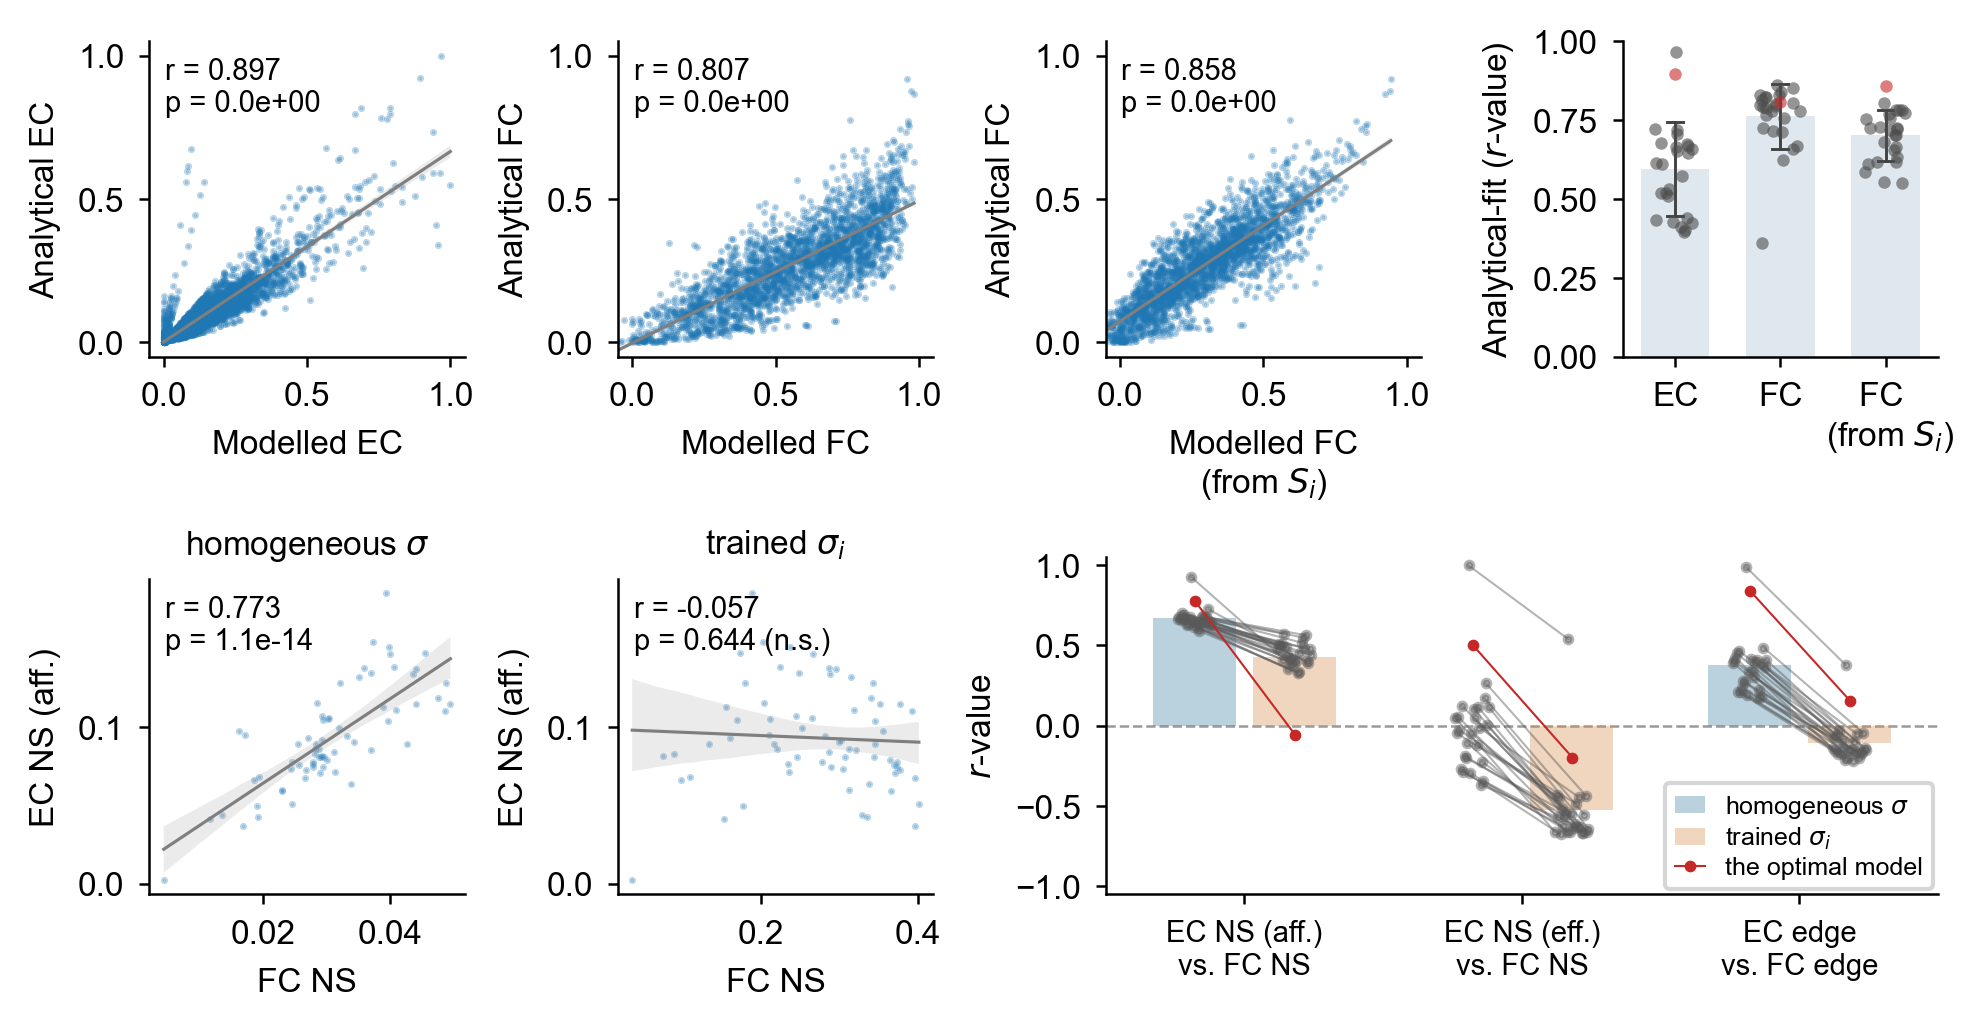

In [39]:
# 2 x 4 总图：上排为理论验证，下排为同质/训练后 sigma 的 EC–FC 比较。
# 下排右侧两列合并；复用前面算好的矩阵、节点强度、相关性和汇总统计。
theory_example_pos = int(np.flatnonzero(theory_case_indices == int(idsbest))[0])
Modelled_EC = modelled_ECs_normalized[theory_example_pos]
Analytical_EC = theory_ECs_normalized[theory_example_pos]
Analytical_FC = theory_FCs[theory_example_pos]
Modelled_FC_outBalloon = modelled_FCs['FCs_outBalloon'][theory_example_pos]
Modelled_FC_outIdentity = modelled_FCs['FCs_outIdentity'][theory_example_pos]

panels = [
    (Modelled_EC, Analytical_EC, mask_modelled_ec_vs_analytical_ec, 'Modelled EC', 'Analytical EC'),
    (Modelled_FC_outBalloon, Analytical_FC, mask_modelled_fc_vs_analytical_fc, 'Modelled FC', 'Analytical FC'),
    (Modelled_FC_outIdentity, Analytical_FC, mask_modelled_fc_vs_analytical_fc, 'Modelled FC\n(from $S_i$)', 'Analytical FC'),
]

# 此函数保持不动，后续scatter使用此函数来画
def plot_scatter(ax,x,y,text_xy=(0,0),mask=None, label='', cmap=plt.colormaps['tab10']):
    if mask is None:
        mask=(~np.isnan(x))&(~np.isnan(y))
    x=np.copy(x[mask])
    y=np.copy(y[mask])
    sns.regplot(ax=ax,x=x,y=y,label=label,scatter_kws={'s':.5,'alpha':.3},line_kws={"color": cmap(7),'alpha':1})
    
    r,p=scipy.stats.pearsonr(x, y)
    if p>0.05:
        text="r = {:.3f}\np = {:.3f} (n.s.)".format(r,p)
    elif p<0.001:
        text="r = {:.3f}\np = {:.1e}".format(r,p)
    else:
        text="r = {:.3f}\np = {:.3f}".format(r,p)
    ax.text(text_xy[0],text_xy[1],text)


fig, axs = plt.subplots(2, 4, figsize=(165 * MM, 85 * MM), layout='constrained')
for ax, (modelled, analytical, mask, xlabel, ylabel) in zip(axs[0], panels):
    plot_scatter(ax, modelled, analytical, (.05, .95), mask=mask, )
    ax.texts[-1].set(transform=ax.transAxes, va='top', fontsize=7)
    ax.set(xlabel=xlabel, ylabel=ylabel)
    gap = 0.05
    ax.set_xlim([0-gap,1+gap])
    ax.set_ylim([0-gap,1+gap])


summary = theory_fit_table[['EC', 'FCs_outBalloon', 'FCs_outIdentity']].rename(
    columns={'FCs_outBalloon': 'FC', 'FCs_outIdentity': 'FC \n (from $S_i$)'})
sns.barplot(ax=axs[0, 3], data=summary, color='#DCE8F1', errorbar='sd', capsize=.15, err_kws={'linewidth': .7}, width=.65)
# best case（当前为 305）单独标红，其余 case 为灰色；每个 case 只绘制一次。
summary_best_index = int(idsbest)
sns.stripplot(ax=axs[0, 3], data=summary.drop(index=summary_best_index),
              color='0.3', size=3, alpha=.6, jitter=.2)
sns.stripplot(ax=axs[0, 3], data=summary.loc[[summary_best_index]],
              color='#C62828', size=3, alpha=.6, jitter=.2, zorder=4)

axs[0, 3].set(xlabel='', ylabel='Analytical-fit ($r$-value)')
# plt.setp(axs[0, 3].get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
axs[0, 3].set_ylim(top=1)

# 下排：两幅节点强度散点图，以及跨两列的配对比较图。
ns_table = theory_compare_hetero_homo_sigma_table
ns_summary = theory_compare_hetero_homo_sigma_summary
ns_colors = ['#3B7EA1', '#D58B45']
ns_best_index = int(idsbest)
ns_best = theory_compare_hetero_homo_sigma_NS[ns_best_index]

ns_grid = axs[1, 2].get_subplotspec().get_gridspec()
for ax in axs[1, 2:]:
    ax.remove()
ns_paired_ax = fig.add_subplot(ns_grid[1, 2:])
ns_fig = fig
ns_axes = np.array([axs[1, 0], axs[1, 1], ns_paired_ax])

for ax, fc_key, xlabel,tit in zip(
    ns_axes[:2], ['FC (sigma=1)', 'FC (trained sigma)'],
    ['FC NS', 'FC NS'],
    ['homogeneous $\sigma$', 'trained $\sigma_i$']
):
    ns_best_fc = ns_best[fc_key]
    plot_scatter(ax, ns_best_fc, ns_best['EC afferent'], (.05, .95))
    ax.texts[-1].set(transform=ax.transAxes, va='top', fontsize=7)
    ax.set(xlabel=xlabel, ylabel='EC NS (aff.)', title=tit)

ns_best_pos = ns_table.index.get_loc(ns_best_index)
ns_offsets = np.linspace(-0.06, 0.06, len(ns_table))
ns_other_cases = np.arange(len(ns_table)) != ns_best_pos
for ns_group, metric in enumerate(['NS afferent', 'NS efferent', 'Edge']):
    ns_columns = [('FC (sigma=1)', metric), ('FC (trained sigma)', metric)]
    ns_values = ns_table.loc[:, ns_columns].to_numpy()
    ns_means = ns_summary.loc['mean', ns_columns].to_numpy()
    ns_pair_x = ns_group + np.array([-0.18, 0.18])
    ns_paired_ax.bar(ns_pair_x, ns_means, width=0.30,
                     color=ns_colors, alpha=0.35, zorder=1)
    ns_case_x = ns_pair_x[:, None] + ns_offsets
    ns_paired_ax.plot(ns_case_x[:, ns_other_cases], ns_values[ns_other_cases].T,
                      'o-', color='0.35', alpha=0.45, lw=0.5, ms=1.8, zorder=2)
    ns_best_line, = ns_paired_ax.plot(ns_case_x[:, ns_best_pos], ns_values[ns_best_pos],
                      'o-', color='#C62828', lw=0.5, ms=1.8, zorder=3)

ns_paired_ax.axhline(0, color='0.6', lw=0.6, ls='--', zorder=0)
ns_paired_ax.set(
    xticks=[0, 1, 2], xticklabels=['EC NS (aff.)\nvs. FC NS', 'EC NS (eff.)\nvs. FC NS', 'EC edge\nvs. FC edge'],
    ylabel='$r$-value', ylim=(-1.05, 1.05),
    yticks=[-1, -0.5, 0, 0.5, 1], xlim=(-0.5, 2.5),
)
ns_paired_ax.tick_params(axis='x', labelsize=7)
ns_paired_ax.legend(
    [ns_paired_ax.patches[0], ns_paired_ax.patches[1], ns_best_line],
    ['homogeneous $\sigma$', 'trained $\sigma_i$', f'the optimal model'],
    loc='lower right', fontsize=6,
    handlelength=1.2, labelspacing=0.2, borderaxespad=0.2,
)

# 所有坐标轴沿用上排的 style_axis；单列面板为正方形，双列面板保留横向空间。
for ax in fig.axes:
    style_axis(ax)
for ax in [*axs[0], *ns_axes[:2]]:
    ax.set_box_aspect(1)
    # 正方形面板靠网格左下角放置，同时对齐同列 y 轴与同行 x 轴。
    ax.set_anchor('SW')

plt.show()


In [40]:
# 三项比较均在同一 case 内配对，对原始相关系数 r 做双侧配对 t 检验。
# 差值及 t 值方向：homogeneous sigma - trained sigma；p 值未作多重比较校正。
ns_paired_ttest_rows = []
for ns_metric, ns_comparison in [
    ('NS afferent', 'EC NS (aff.) vs. FC NS'),
    ('NS efferent', 'EC NS (eff.) vs. FC NS'),
    ('Edge', 'EC edge vs. FC edge'),
]:
    ns_pairs = ns_table.loc[:, [
        ('FC (sigma=1)', ns_metric), ('FC (trained sigma)', ns_metric),
    ]].to_numpy(dtype=float)
    # 同时排除任一条件含 NaN/inf 的整对数据，保留 case 配对关系。
    ns_pairs = ns_pairs[np.isfinite(ns_pairs).all(axis=1)]
    ns_n_pairs = len(ns_pairs)
    if ns_n_pairs >= 2:
        ns_t_stat, ns_p_value = scipy.stats.ttest_rel(
            ns_pairs[:, 0], ns_pairs[:, 1], alternative='two-sided',
        )
    else:
        ns_t_stat, ns_p_value = np.nan, np.nan
    ns_paired_ttest_rows.append({
        'comparison': ns_comparison,
        'n_pairs': ns_n_pairs,
        'mean_homogeneous': ns_pairs[:, 0].mean() if ns_n_pairs else np.nan,
        'mean_trained': ns_pairs[:, 1].mean() if ns_n_pairs else np.nan,
        'mean_difference': (ns_pairs[:, 0] - ns_pairs[:, 1]).mean() if ns_n_pairs else np.nan,
        't': ns_t_stat,
        'df': ns_n_pairs - 1 if ns_n_pairs >= 2 else np.nan,
        'p_two_sided': ns_p_value,
    })

ns_paired_ttests = pd.DataFrame(ns_paired_ttest_rows).set_index('comparison')
print('Paired t-tests: homogeneous sigma - trained sigma; two-sided, unadjusted p-values')
with pd.option_context('display.max_columns', None, 'display.float_format', '{:.6g}'.format):
    display(ns_paired_ttests)


Paired t-tests: homogeneous sigma - trained sigma; two-sided, unadjusted p-values


,n_pairs,mean_homogeneous,mean_trained,mean_difference,t,df,p_two_sided
comparison,,,,,,,
EC NS (aff.) vs. FC NS,26,0.670112,0.426993,0.243119,8.36013,25,1.04313e-08
EC NS (eff.) vs. FC NS,26,-0.000128783,-0.525061,0.524932,16.4885,25,6.07322e-15
EC edge vs. FC edge,26,0.375705,-0.108288,0.483993,27.3541,25,3.76289e-20
